<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/OT-day1/OT_Day1_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ONNX·TensorRT Day 1 — ONNX 첫걸음: 내보내고, 보고, 실행하기

**온디바이스 AI · ONNX·TensorRT 1/5 · 11/4(수)** · Google Colab (하드웨어 없음) · PyTorch · ONNX · ONNX Runtime · Netron

Vision 기본 모델 Day 5 에서 `mnv3s.onnx` 를 **한 번** 만들어 봤습니다. 오늘은 그 과정을 아주 작은 모델부터 천천히, **한 단계씩** 다시 밟습니다. 모든 모델에 같은 4단계를 반복합니다.

> **내보내기** (`torch.onnx.export`) → **열어보기** (Netron) → **실행하기** (ONNX Runtime) → **확인하기** (PyTorch 와 같은가?)

오늘의 목표

1. 모델을 **학습하는 곳**과 **실행하는 곳**이 왜 다른지, ONNX 가 그 사이에서 하는 일을 말할 수 있다.
2. `nn.Linear(3, 2)` 하나짜리 모델을 ONNX 파일로 내보내고 **파일 안에 무엇이 들었는지** 설명할 수 있다.
3. **Netron** 으로 노드 · 화살표 · 가중치 · 입출력 shape 를 읽을 수 있다.
4. **ONNX Runtime** 으로 실행하고 PyTorch 결과와 `np.allclose` 로 비교할 수 있다.
5. 입력 · 출력에 **이름**을 붙이고, 이미지 입력 모양 **(N, C, H, W)** 를 맞출 수 있다.
6. MNIST CNN 과 MobileNetV3 로 **사진 한 장 추론** — 전처리부터 top-5 까지 직접 만든다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | 왜 ONNX 인가 — 학습하는 곳 vs 실행하는 곳 |
| 2 | 10:00–10:50 | 첫 ONNX 만들기 — `nn.Linear(3, 2)` 내보내기 |
| 3 | 11:00–11:50 | Netron 으로 보기 — 노드 · 화살표 · 가중치 |
| 4 | 13:00–13:50 | ONNX Runtime 으로 실행 — PyTorch 와 같은가? |
| 5 | 14:00–14:50 | 이름 붙이기 · 입력 shape (N, C, H, W) |
| 6 | 15:00–15:50 | MNIST CNN 내보내기 — 같은 4단계를 큰 모델에 |
| 7 | 16:00–16:50 | 이미지 한 장 추론 — 전처리 6단계 · MobileNetV3 |
| 8 | 17:00–17:50 | 미니 프로젝트 — 혼자서 4단계 · 채점 |

**노트북 사용법**

1. *런타임 → 런타임 유형 변경 → T4 GPU* 를 고르고, *파일 → Drive에 사본 저장* 후 사본에서 작업합니다. (오늘은 CPU 로도 모두 실행됩니다.)
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행하고, 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다.
3. 막히면 **🔒 정답 보기** 셀을 실행하세요. 🖼 그림 셀은 실행하지 않아도 그림이 보입니다.
4. 매 교시는 **보기 → 따라하기 → 바꿔보기** 순서입니다. `🔁 바꿔보기` 셀은 숫자 하나만 바꿔 결과가 어떻게 달라지는지 관찰합니다.
5. 8교시 미니 프로젝트는 이 노트북 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/OT_Day1.pdf](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/OT_Day1.pdf) |
| 🔭 Netron (브라우저용) | [https://netron.app](https://netron.app) — `.onnx` 파일을 끌어다 놓으면 그래프가 보입니다 |

**오늘의 데이터 · 모델** — 직접 만드는 작은 모델 `tiny` · `mlp`, VB Day 1 의 **SimpleConvNet** (MNIST, 학습된 가중치 `mnist_cnn.pt` 제공), VB Day 5 의 **MobileNetV3-Small** (`mnv3s.onnx` — 없으면 노트북이 다시 만듭니다), OpenCV 예제 사진 3장.

In [ ]:
# ▶ 설치 셀 — ONNX · ONNX Runtime · Netron. 처음 한 번, 약 30초
%pip install -q onnx onnxruntime onnxscript netron

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, time, inspect, warnings, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import onnx
import onnxruntime as ort

warnings.filterwarnings("ignore")              # export 때 나오는 긴 경고 숨기기
np.set_printoptions(precision=4, suppress=True)
torch.manual_seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/OT-day1"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1"

# 이 과정은 '기존 방식(TorchScript)' export 를 씁니다 — 그래프가 단순해서 처음 배우기 좋습니다.
# PyTorch 버전에 따라 dynamo 옵션이 없으면 빈 딕셔너리가 됩니다. export 할 때마다 **EXPORT_KW 를 붙입니다.
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버(GitHub Pages → GitHub 원본 순)에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 강사에게 받은 파일을 왼쪽 📁 파일 창의 data 폴더에 올린 뒤 다시 실행하세요.")
    return path

def show_netron(path, port=8081, height=520):
    """Colab 안에 Netron 창을 띄운다. Colab 이 아니면 netron.app 안내"""
    try:
        import netron
        from google.colab import output
        netron.start(path, address=("localhost", port), browse=False)
        output.serve_kernel_port_as_iframe(port, height=str(height))
    except ImportError:
        print(f"Colab 이 아닙니다 → {path} 를 내려받아 https://netron.app 에 끌어다 놓으세요.")

print("PyTorch", torch.__version__, "| ONNX", onnx.__version__, "| ONNX Runtime", ort.__version__)
print("export 방식:", "기존(TorchScript)" if EXPORT_KW else "기본값")

## 1교시 — 왜 ONNX 인가: 학습하는 곳 vs 실행하는 곳

### 이번 과목의 5일 — 하루에 한 계단

| 일차 | 날짜 | 계단 | 만드는 것 |
|---|---|---|---|
| **Day 1** | 11/4(수) | **ONNX 첫걸음** | 내보내기 → Netron → ONNX Runtime → 확인, 사진 한 장 추론 |
| Day 2 | 11/5(목) | ONNX 속 들여다보기 | 그래프를 코드로 읽기, export 오류 고치기, 배치 크기 자유롭게 |
| Day 3 | 11/6(금) | ONNX Runtime 으로 빠르게 | 측정 함수 `bench()`, 스레드 · 최적화 · CPU→GPU 성능표 |
| Day 4 | 11/10(화) | TensorRT 첫걸음 | ONNX → TensorRT 엔진, FP16 |
| Day 5 | 11/11(수) | 탐지 모델 · 종합 프로젝트 | YOLOv8n TensorRT 로 위험구역 침입 감지 |

> 🎬 **애니메이션** [D1-1 학습 vs 실행](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html#d1-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

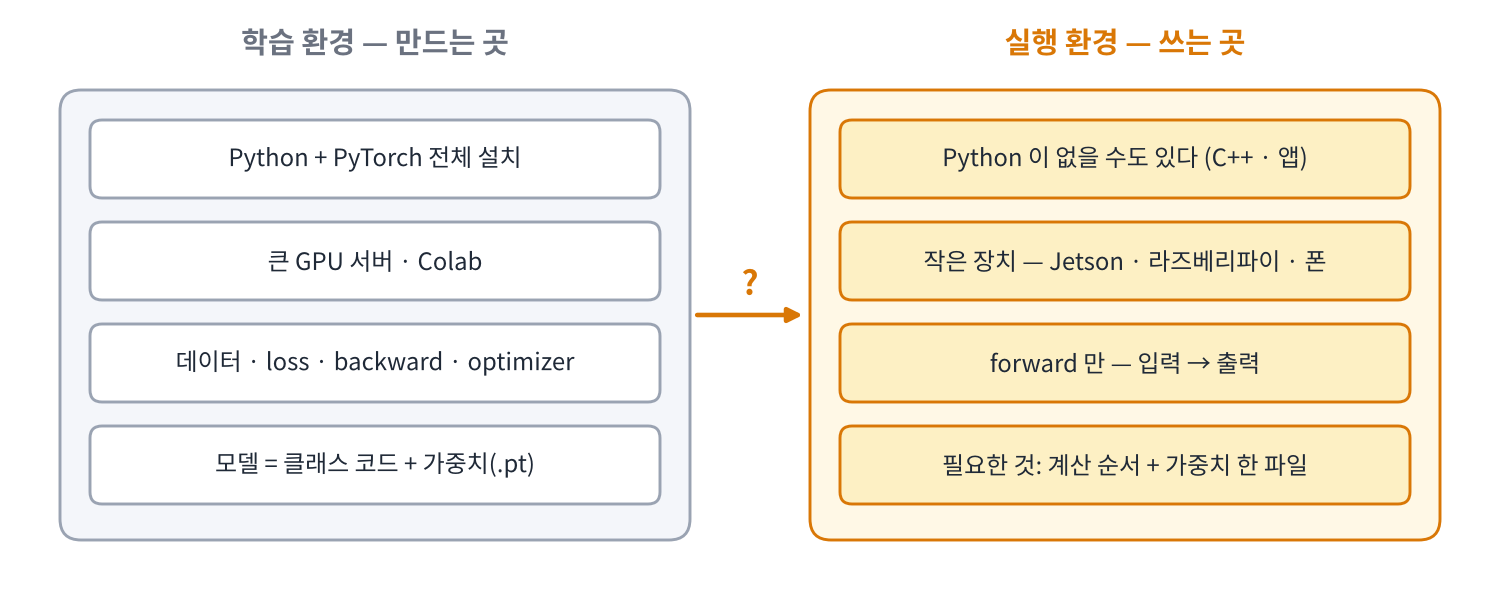

In [ ]:
#@title 🖼 그림 — 학습 환경과 실행 환경은 다르다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f1_why.png", embed=True, width=820))

지금까지 모델은 **Colab 에서 만들고 Colab 에서 썼습니다.** 하지만 현장 안전 모니터링 카메라 옆의 작은 장치에는 Python 도, PyTorch 도 없을 수 있습니다. 실행하는 쪽에 필요한 것은 딱 두 가지입니다.

1. **계산 순서** — 입력에 무엇을 곱하고, 더하고, 어떤 함수를 거치는지
2. **가중치** — 학습으로 얻은 숫자들

**ONNX** (Open Neural Network Exchange) 는 이 두 가지를 **한 파일**에 담는 공용 형식입니다. 비유하면 **누구나 읽을 수 있는 설계도**입니다. 설계도만 있으면 어느 공장(실행기)에서든 같은 제품(결과)을 만들 수 있습니다.

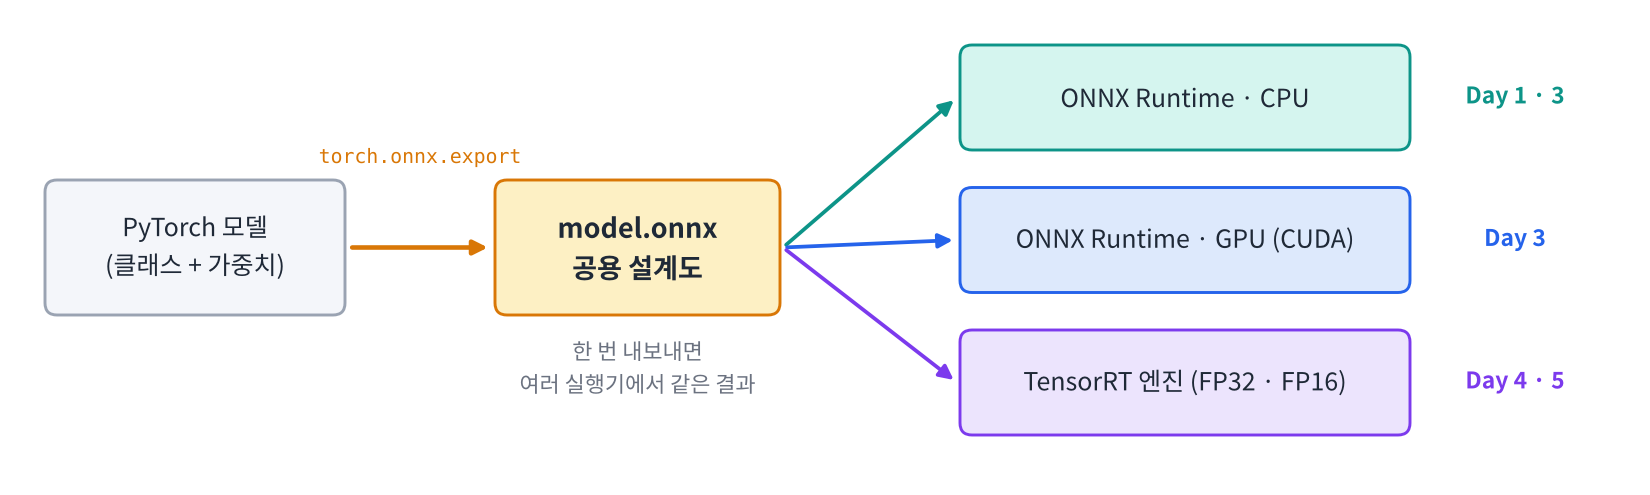

In [ ]:
#@title 🖼 그림 — PyTorch → ONNX → 여러 실행기 (이번 과목의 길)
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f1_path.png", embed=True, width=860))

### `.pt` 파일에는 무엇이 들었나

VB 과정에서는 `torch.save(model.state_dict(), "cnn.pt")` 로 저장했습니다. 이 파일을 열어 봅시다. 먼저 아주 작은 모델 `tiny` 를 만듭니다 — 입력 3개를 받아 출력 2개를 내는 `nn.Linear(3, 2)` 하나뿐입니다.

In [ ]:
tiny = nn.Linear(3, 2)
torch.save(tiny.state_dict(), "tiny.pt")
print(tiny)
print("파일 크기:", os.path.getsize("tiny.pt"), "bytes")

**문제 1-1** `tiny.pt` 를 다시 읽어 안에 든 **이름(key)** 과 **shape** 를 출력하세요. `state_dict` 는 파이썬 딕셔너리처럼 다룹니다.

In [ ]:
sd = torch.load("tiny.pt")
keys = list(sd.____())
for k in keys:
    print(k, tuple(sd[k].shape))

In [ ]:
assert keys == ["weight", "bias"] and tuple(sd["weight"].shape) == (2, 3)
print("✅", keys)

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACnNkID0gdG9yY2gubG9hZCgidGlueS5wdCIpCmtleXMgPSBsaXN0KHNk"
    "LmtleXMoKSkKZm9yIGsgaW4ga2V5czoKICAgIHByaW50KGssIHR1cGxlKHNkW2tdLnNoYXBlKSkKCvCfkqEg7ZW0"
    "7ISkCu2MjOydvOyXkOuKlCB3ZWlnaHQgKDIsIDMpIOqzvCBiaWFzICgyKSDigJQg7Iir7J6QIDjqsJzrp4wg7J6I"
    "7Iq164uI64ukLgoi7J20IOyIq+yekOuhnCDrrLTsl4fsnYQg7Ja065akIOyInOyEnOuhnCDqs4TsgrDtlZjripTs"
    "p4AiIOuKlCDsl4bsirXri4jri6QuIOq3uOuemOyEnCAucHQg66W8IOyTsOugpOuptCBubi5MaW5lYXIoMywgMikg"
    "66W8IOunjOuTnOuKlArtjIzsnbTsjawg7L2U65Oc6rCAIOuwmOuTnOyLnCDsnojslrTslbwg7ZWp64uI64ukLiBP"
    "Tk5YIOuKlCDqs4TsgrAg7Iic7IScKOq3uOuemO2UhCkg6rmM7KeAIO2VqOq7mCDsoIDsnqXtlanri4jri6Qu"
).decode("utf-8"))

### 학습할 때만 필요한 것, 실행할 때도 필요한 것

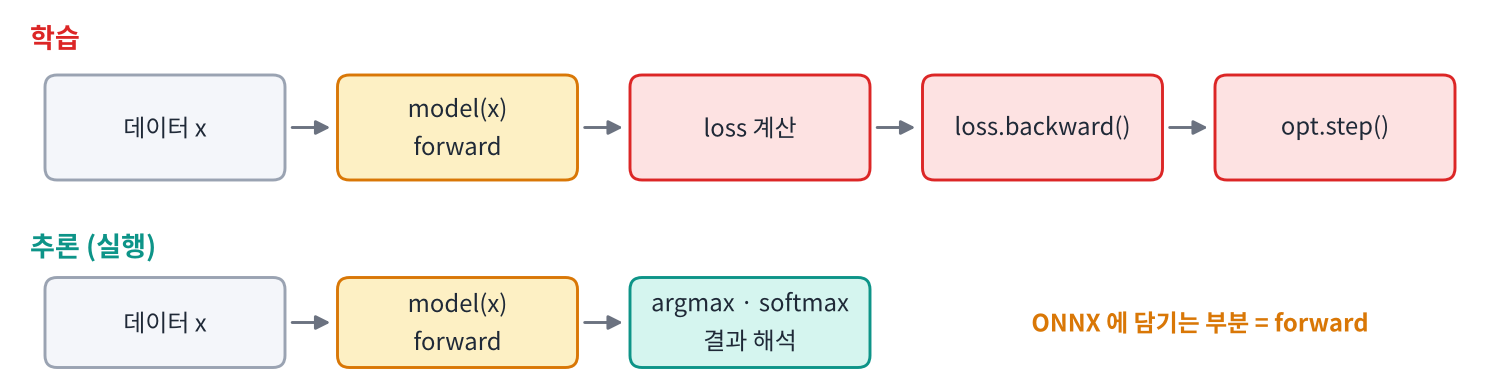

In [ ]:
#@title 🖼 그림 — 학습은 5단계, 추론(실행)은 forward 만 — ONNX 에는 forward 만 담긴다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f1_train_infer.png", embed=True, width=820))

**문제 1-2** 아래 6개 단계 중 **실행(추론) 할 때도 필요한 것**의 번호만 `infer_steps` 에 쓰세요.

| 번호 | 단계 |
|---|---|
| 0 | 이미지를 텐서로 바꾸기 (전처리) |
| 1 | `model(x)` — forward |
| 2 | `loss = loss_fn(logits, y)` |
| 3 | `loss.backward()` |
| 4 | `opt.step()` |
| 5 | `logits.argmax(1)` — 결과 해석 |

In [ ]:
infer_steps = [____]

In [ ]:
assert sorted(infer_steps) == [0, 1, 5]; print("✅ 추론 =", sorted(infer_steps))

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACmluZmVyX3N0ZXBzID0gWzAsIDEsIDVdCgrwn5KhIO2VtOyEpApsb3Nz"
    "IMK3IGJhY2t3YXJkIMK3IHN0ZXAg7J2AIOygleuLtSh5KSDsnbQg7J6I7Ja07JW8IO2VmOqzoCDqsIDspJHsuZjr"
    "pbwg67CU6r6464qUICftlZnsirUnIOuLqOqzhOyeheuLiOuLpC4K7Iuk7ZaJ7ZWgIOuVjOuKlCDsnoXroKXsnYQg"
    "7KCE7LKY66as7ZW0IGZvcndhcmQg7ZWY6rOgIOqysOqzvOulvCDtlbTshJ3tlZjripQg6rKD67+QIOKAlCDqt7jr"
    "npjshJwgT05OWCDtjIzsnbzsl5DripQgZm9yd2FyZCDrp4wg64u06rmB64uI64ukLgrsoITsspjrpqwgwrcg6rKw"
    "6rO8IO2VtOyEneydgCBPTk5YIOuwluydmCDsvZTrk5wo7Jik64qYIDfqtZDsi5wpIOuhnCDrlLDroZwg66eM65Ok"
    "7Ja07JW8IO2VnOuLpOuKlCDsoJDrj4Qg6riw7Ja17ZWY7IS47JqULg=="
).decode("utf-8"))

#### ⚠️ 자주 하는 오해

- "ONNX 로 바꾸면 무조건 빨라진다" → 아닙니다. ONNX 는 **형식(설계도)** 이고, 빠르기는 실행기가 정합니다 (Day 3 · 4 에서 측정).
- "ONNX 파일로 학습을 이어서 할 수 있다" → 이 과목의 ONNX 는 forward 만 담습니다. 학습은 PyTorch 에서.
- "전처리도 모델에 들어 있다" → 보통 아닙니다. `/255` · 정규화 · 크기 맞추기는 실행 쪽 코드가 해야 합니다.

#### 📌 1교시 정리

- 학습하는 곳(Colab · PyTorch) 과 실행하는 곳(작은 장치 · 다른 언어) 은 다르다.
- `.pt` = 가중치만, 계산 순서는 파이썬 코드에 있다. **ONNX = 계산 순서 + 가중치, 한 파일.**
- 추론에 필요한 것은 전처리 → forward → 결과 해석. ONNX 에는 forward 가 들어간다.

## 2교시 — 첫 ONNX 만들기: `nn.Linear(3, 2)` 내보내기

오늘 가장 중요한 한 줄은 `torch.onnx.export` 입니다. 4단계로 나눠 한 줄씩 갑니다.

> 🎬 **애니메이션** [D1-2 export 는 녹화다](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html#d1-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

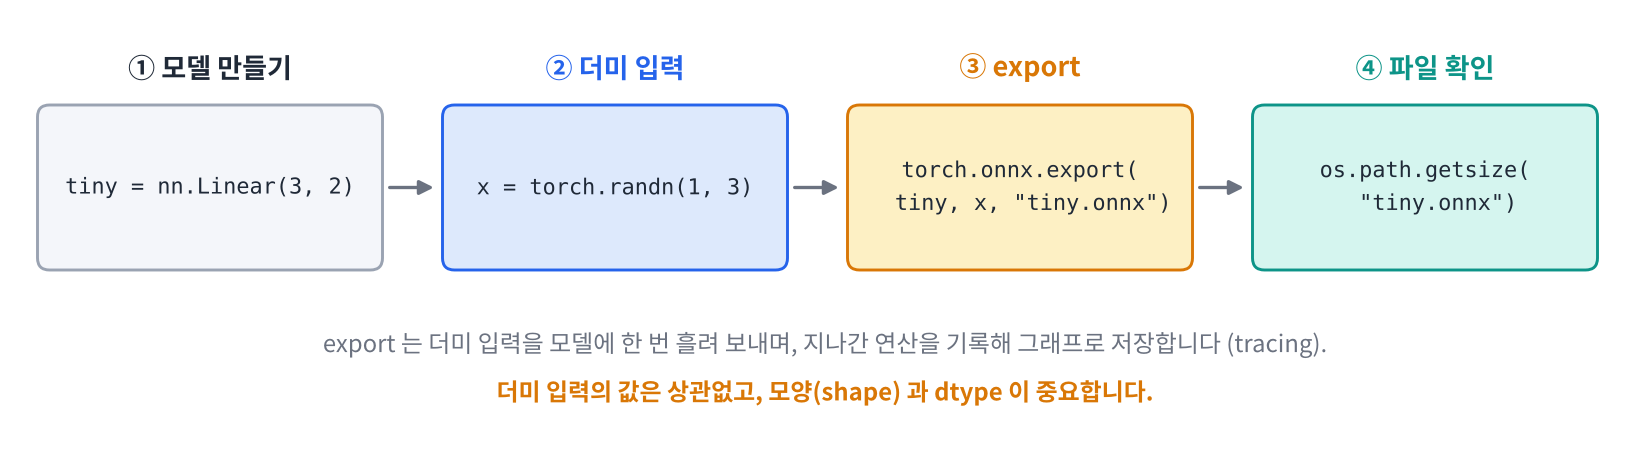

In [ ]:
#@title 🖼 그림 — ONNX 내보내기 4단계
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f2_export.png", embed=True, width=860))

### ① 모델 만들기 — 숫자를 직접 정해 둡니다

결과를 손으로 확인할 수 있도록 가중치를 직접 넣습니다.

$$W = \begin{bmatrix} 1 & 2 & 3 \\ 0 & -1 & 1 \end{bmatrix}, \quad b = [0.5,\ -0.5], \quad y = xW^T + b$$

In [ ]:
tiny = nn.Linear(3, 2)
with torch.no_grad():                                   # 가중치를 직접 넣을 때는 기록을 끈다
    tiny.weight.copy_(torch.tensor([[1., 2., 3.], [0., -1., 1.]]))
    tiny.bias.copy_(torch.tensor([0.5, -0.5]))
tiny.eval()                                             # 실행 모드 (Dropout · BN 이 있으면 중요)

x1 = torch.tensor([[1., 1., 1.]])
print("tiny([1, 1, 1]) =", tiny(x1).detach().numpy())  # 1+2+3+0.5 = 6.5,  0-1+1-0.5 = -0.5

**문제 2-1** **② 더미 입력** — export 는 입력을 **한 번 흘려 보내며** 지나간 연산을 기록합니다 (녹화). 값은 아무거나 괜찮지만 **모양(shape)** 이 맞아야 합니다. 이미지 1장 · 특징 3개 → shape `(1, 3)` 인 난수 텐서를 만드세요.

In [ ]:
dummy = torch.randn(____, ____)
print(dummy.shape, dummy.dtype)

In [ ]:
assert tuple(dummy.shape) == (1, 3) and dummy.dtype == torch.float32; print("✅", tuple(dummy.shape))

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmR1bW15ID0gdG9yY2gucmFuZG4oMSwgMykKcHJpbnQoZHVtbXkuc2hh"
    "cGUsIGR1bW15LmR0eXBlKQoK8J+SoSDtlbTshKQK7LKrIOuyiOynuCAxIOydgCDrsLDsuZgo66qHIOqwnOulvCDt"
    "lZwg67KI7JeQKSwgMyDsnYAgbm4uTGluZWFyIOydmCBpbl9mZWF0dXJlcy4gZHR5cGUg7J2AIGZsb2F0MzIg7Jes"
    "7JW8IO2VqeuLiOuLpArigJQg7Jes6riw7IScIGZsb2F0NjQg66W8IOyTsOuptCBPTk5YIO2MjOydvOydmCDsnoXr"
    "oKXrj4QgZmxvYXQ2NCDroZwg6rWz7Ja0IOuyhOumveuLiOuLpC4="
).decode("utf-8"))

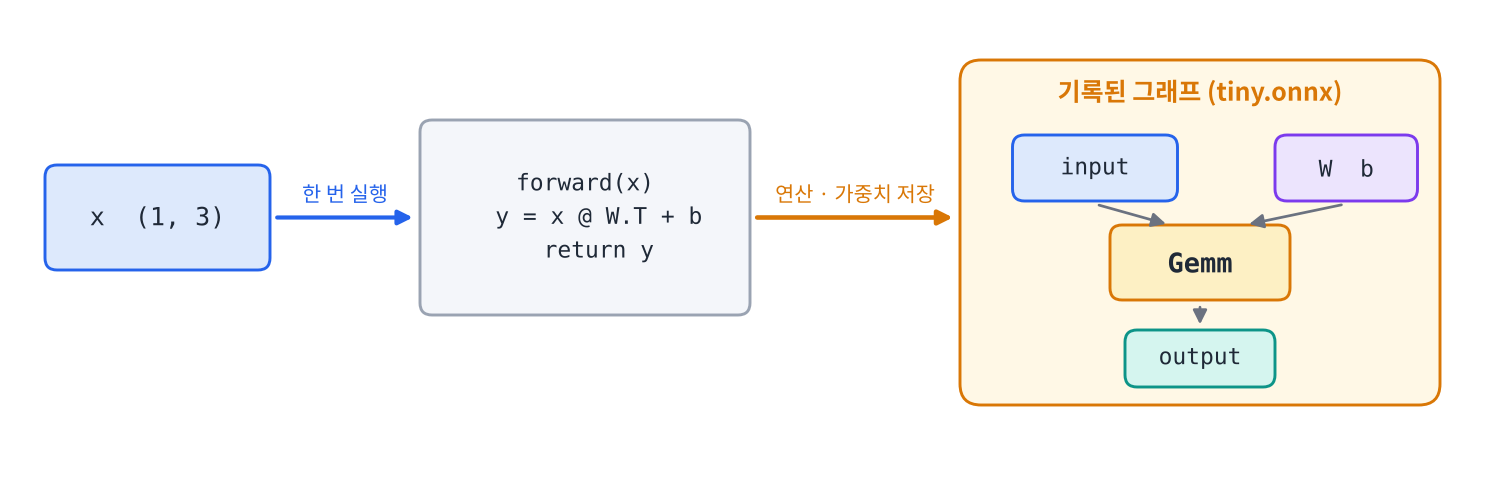

In [ ]:
#@title 🖼 그림 — export = 더미 입력으로 한 번 실행하며 연산을 녹화
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f2_trace.png", embed=True, width=820))

**문제 2-2** **③ export** — `torch.onnx.export(모델, 더미 입력, 파일 이름, **EXPORT_KW)` 순서로 씁니다. `tiny` 를 `tiny.onnx` 로 내보내세요.

In [ ]:
torch.onnx.export(____, ____, "tiny.onnx", **EXPORT_KW)
print("저장:", "tiny.onnx")

In [ ]:
m = onnx.load("tiny.onnx"); onnx.checker.check_model(m)
print("✅ tiny.onnx —", [n.op_type for n in m.graph.node])

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACnRvcmNoLm9ubnguZXhwb3J0KHRpbnksIGR1bW15LCAidGlueS5vbm54"
    "IiwgKipFWFBPUlRfS1cpCnByaW50KCLsoIDsnqU6IiwgInRpbnkub25ueCIpCgrwn5KhIO2VtOyEpArrqqjrjbgg"
    "wrcg642U66+4IOyeheugpSDCtyDtjIzsnbwg7J2066aEIOyInOyEnC4gb25ueC5jaGVja2VyLmNoZWNrX21vZGVs"
    "IOydgCDtjIzsnbwg7ZiV7Iud7J20IOyYrOuwlOuluOyngCDqsoDsgqztlanri4jri6QgKOyYpOulmOqwgCDsl4bs"
    "nLzrqbQg7Ya16rO8KS4KKipFWFBPUlRfS1cg64qUIO2ZmOqyvSDshYDsl5DshJwg66eM65OgIOyYteyFmCDigJQg"
    "7Jik64qY7J2AIOunpOuyiCDqt7jrjIDroZwg67aZ7J2066m0IOuQqeuLiOuLpC4="
).decode("utf-8"))

### ④ 파일 확인 — 크기로 내용 짐작하기

가중치는 float32 = 숫자 하나에 **4 byte** 입니다.

**문제 2-3** `tiny` 의 파라미터 수와, 그 숫자들이 차지하는 byte 수를 구하세요. 그리고 파일 크기와 비교합니다.

In [ ]:
n_params = sum(p.____() for p in tiny.parameters())
param_bytes = n_params * ____
file_bytes = os.path.getsize("tiny.onnx")
print(f"파라미터 {n_params} 개 × 4 B = {param_bytes} B  |  tiny.onnx {file_bytes} B")

In [ ]:
assert n_params == 8 and param_bytes == 32; print("✅ 나머지", file_bytes - param_bytes, "B 는 그래프 · 이름 · 버전 정보")

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACm5fcGFyYW1zID0gc3VtKHAubnVtZWwoKSBmb3IgcCBpbiB0aW55LnBh"
    "cmFtZXRlcnMoKSkKcGFyYW1fYnl0ZXMgPSBuX3BhcmFtcyAqIDQKZmlsZV9ieXRlcyA9IG9zLnBhdGguZ2V0c2l6"
    "ZSgidGlueS5vbm54IikKcHJpbnQoZiLtjIzrnbzrr7jthLAge25fcGFyYW1zfSDqsJwgw5cgNCBCID0ge3BhcmFt"
    "X2J5dGVzfSBCICB8ICB0aW55Lm9ubngge2ZpbGVfYnl0ZXN9IEIiKQoK8J+SoSDtlbTshKQKd2VpZ2h0IDYgKyBi"
    "aWFzIDIgPSA4IOqwnCDDlyA0IEIgPSAzMiBCLiDtjIzsnbzsnbQg642UIO2BsCDsnbTsnKDripQgJ+qzhOyCsCDs"
    "iJzshJwo6re4656Y7ZSEKScsIOyehey2nOugpSDsnbTrpoQgwrcgc2hhcGUsCm9wc2V0IOuyhOyghCDqsJnsnYAg"
    "7ISk66qF7J20IO2VqOq7mCDrk6TslrQg7J6I6riwIOuVjOusuOyeheuLiOuLpC4g7YGwIOuqqOuNuOyXkOyEnOuK"
    "lCDsnbQg67aA67aE7J20IOustOyLnO2VoCDrp4ztgbwg7J6R7JWE7KC4IO2MjOydvCDtgazquLAg4omIIO2MjOud"
    "vOuvuO2EsCDDlyA0IEIg6rCAIOuQqeuLiOuLpCAoNuq1kOyLnCku"
).decode("utf-8"))

### 🔁 바꿔보기 — 출력 개수를 2 → 5 로

아래 셀의 `OUT` 만 바꿔 실행해 보세요. 파라미터 수와 파일 크기가 어떻게 변하나요?

In [ ]:
OUT = 5                                     # 2, 5, 100 으로 바꿔 보세요
t2 = nn.Linear(3, OUT).eval()
torch.onnx.export(t2, torch.randn(1, 3), "tiny_out.onnx", **EXPORT_KW)
n = sum(p.numel() for p in t2.parameters())
print(f"Linear(3, {OUT}): 파라미터 {n} 개 → {n * 4} B | 파일 {os.path.getsize('tiny_out.onnx')} B")

#### ⚠️ 자주 하는 실수

- 더미 입력을 `torch.randn(3)` 처럼 **배치 축 없이** 만듦 → 실행할 때도 배치 축이 없는 입력만 받는 파일이 됩니다.
- `model.eval()` 을 빼먹음 → export 자체는 기본값으로 실행 모드 그래프를 녹화하지만, **비교 기준인 PyTorch 결과**가 학습 모드(Dropout · BN 배치 통계)로 계산되어 4교시 비교가 어긋납니다. 오늘 모델은 영향 없지만 습관으로 export 전에 `eval()`.
- export 결과 파일 이름 오타 → 다음 셀에서 `FileNotFoundError`. 왼쪽 📁 파일 창에서 확인하세요.

#### 📌 2교시 정리

- `torch.onnx.export(model, dummy, "x.onnx")` — 더미 입력으로 **한 번 실행하며 연산을 녹화**한다.
- 더미 입력은 **값은 상관없고 shape · dtype 이 중요**하다. (1, 3) float32.
- 파일 크기 ≈ 파라미터 수 × 4 B + 그래프 설명.

## 3교시 — Netron 으로 보기: 노드 · 화살표 · 가중치

**Netron** 은 ONNX 파일을 그림으로 보여 주는 뷰어입니다. 노드를 클릭하면 가중치 값까지 볼 수 있습니다.

> 🎬 **애니메이션** [D1-3 Netron 그래프 읽기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html#d1-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 보기 — Colab 안에서 Netron 열기

아래 셀을 실행하면 노트북 안에 Netron 창이 뜹니다. 창이 안 보이면 왼쪽 📁 파일 창에서 `tiny.onnx` 를 내려받아 [netron.app](https://netron.app) 에 끌어다 놓으세요.

In [ ]:
show_netron("tiny.onnx", port=8081)

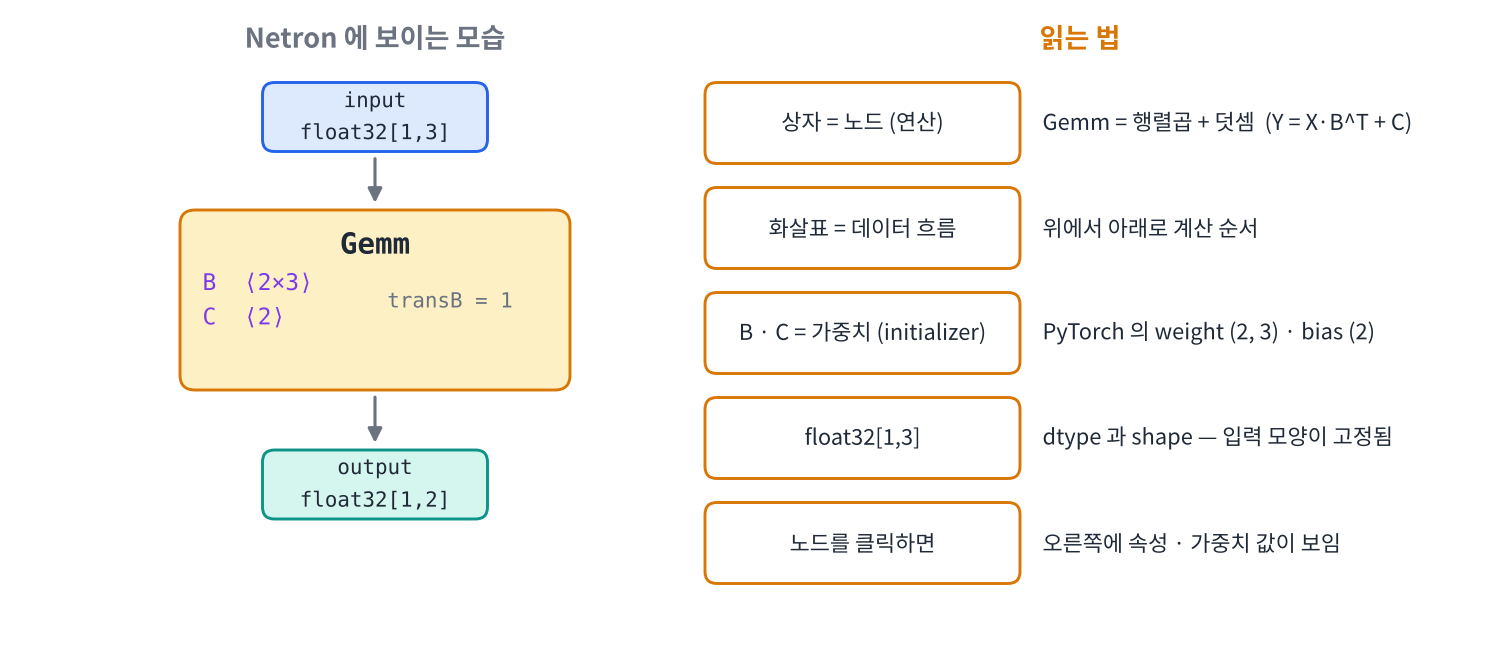

In [ ]:
#@title 🖼 그림 — Netron 에서 tiny.onnx 읽는 법
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f3_tiny_graph.png", embed=True, width=860))

Netron 화면에서 확인할 것 — **Gemm 상자를 클릭**해 보세요.

1. 상자가 몇 개인가? → **1개 (Gemm)**. `Gemm` = General Matrix Multiply, 행렬곱 + 덧셈.
2. `B` 와 `C` 는 무엇인가? → B = weight `⟨2×3⟩`, C = bias `⟨2⟩`. B 를 클릭하면 숫자 `1, 2, 3, 0, -1, 1` 이 보입니다.
3. 입력 · 출력의 shape 는? → `float32[1,3]` → `float32[1,2]`.
4. 입력 이름이 `onnx::Gemm_0` 처럼 이상합니다 → 5교시에서 고칩니다.

### 따라하기 — 같은 내용을 코드로 확인

Netron 에서 본 것을 `onnx.load` 로도 꺼낼 수 있습니다. (Day 2 에서 깊게 합니다. 오늘은 맛보기.)

In [ ]:
m = onnx.load("tiny.onnx")
print(onnx.helper.printable_graph(m.graph))     # 그래프를 글로 보기

**문제 3-1** `m.graph.node` 는 노드(상자) 목록입니다. 각 노드의 **종류**(`op_type`) 를 리스트로 모으세요.

In [ ]:
node_types = [n.____ for n in m.graph.node]
print(node_types)

In [ ]:
assert node_types == ["Gemm"]; print("✅", node_types)

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACm5vZGVfdHlwZXMgPSBbbi5vcF90eXBlIGZvciBuIGluIG0uZ3JhcGgu"
    "bm9kZV0KcHJpbnQobm9kZV90eXBlcykKCvCfkqEg7ZW07ISkCk5ldHJvbiDsnZgg7IOB7J6QIOydtOumhCA9IG9w"
    "X3R5cGUuIG5uLkxpbmVhciDripQgT05OWCDsl5DshJwgR2VtbSDrhbjrk5wg7ZWY64KY6rCAIOuQqeuLiOuLpC4="
).decode("utf-8"))

**문제 3-2** Netron 에서 본 `B ⟨2×3⟩` 가 PyTorch 의 `tiny.weight` 와 같은 모양인지 확인하세요. ONNX 파일 안의 가중치는 `m.graph.initializer` 에 있고, `onnx.numpy_helper.to_array` 로 NumPy 배열이 됩니다.

In [ ]:
W_torch = tuple(tiny.weight.____)
W_onnx = onnx.numpy_helper.to_array(m.graph.initializer[0])
print("PyTorch weight", W_torch, "| ONNX B", W_onnx.shape)
print(W_onnx)

In [ ]:
assert W_torch == (2, 3) == W_onnx.shape and np.allclose(W_onnx, [[1, 2, 3], [0, -1, 1]]); print("✅ 같은 숫자, 같은 모양")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACldfdG9yY2ggPSB0dXBsZSh0aW55LndlaWdodC5zaGFwZSkKV19vbm54"
    "ID0gb25ueC5udW1weV9oZWxwZXIudG9fYXJyYXkobS5ncmFwaC5pbml0aWFsaXplclswXSkKcHJpbnQoIlB5VG9y"
    "Y2ggd2VpZ2h0IiwgV190b3JjaCwgInwgT05OWCBCIiwgV19vbm54LnNoYXBlKQpwcmludChXX29ubngpCgrwn5Kh"
    "IO2VtOyEpApQeVRvcmNoIOuKlCB3ZWlnaHQg66W8IChvdXQsIGluKSA9ICgyLCAzKSDsnLzroZwg7KCA7J6l7ZWY"
    "6rOgIHggQCBXLlQg66GcIOqzhOyCsO2VqeuLiOuLpC4K6re4656Y7IScIEdlbW0g64W465Oc7JeQIHRyYW5zQiA9"
    "IDEgKEIg66W8IOyghOy5mO2VtOyEnCDqs7HtlZjrnbwpIOyGjeyEseydtCDrtpnslrQg7J6I7Iq164uI64ukIOKA"
    "lCBOZXRyb24g7JeQ7IScIEdlbW0g7J2EIO2BtOumre2VmOuptCDrs7TsnoXri4jri6Qu"
).decode("utf-8"))

### 바꿔보기 — 층을 하나 더 쌓으면 그림이 어떻게 바뀔까

`Linear(3, 4) → ReLU → Linear(4, 2)` 의 2층 MLP 를 만듭니다. **실행하기 전에** Netron 에 보일 상자 순서를 예측하세요.

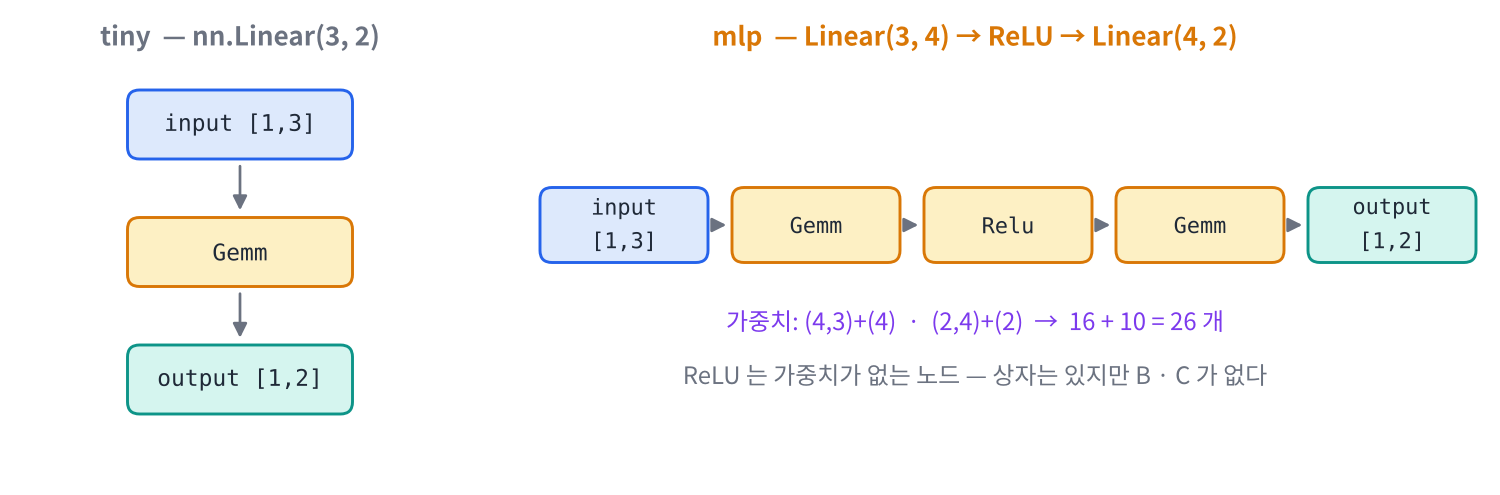

In [ ]:
#@title 🖼 그림 — 층을 쌓으면 상자가 늘어난다 — ReLU 는 가중치 없는 상자
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f3_mlp.png", embed=True, width=860))

**문제 3-3** `mlp.onnx` 의 노드 종류를 **실행 전에 예측**해 `predict` 에 쓰고, 아래 셀로 확인하세요.

In [ ]:
mlp = nn.Sequential(nn.Linear(3, 4), nn.ReLU(), nn.Linear(4, 2)).eval()
torch.onnx.export(mlp, torch.randn(1, 3), "mlp.onnx", **EXPORT_KW)
predict = [____]                      # 예: ["Gemm", ...]

In [ ]:
real = [n.op_type for n in onnx.load("mlp.onnx").graph.node]
assert predict == real; print("✅ 예측 성공:", real)

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSACm1scCA9IG5uLlNlcXVlbnRpYWwobm4uTGluZWFyKDMsIDQpLCBubi5S"
    "ZUxVKCksIG5uLkxpbmVhcig0LCAyKSkuZXZhbCgpCnRvcmNoLm9ubnguZXhwb3J0KG1scCwgdG9yY2gucmFuZG4o"
    "MSwgMyksICJtbHAub25ueCIsICoqRVhQT1JUX0tXKQpwcmVkaWN0ID0gWyJHZW1tIiwgIlJlbHUiLCAiR2VtbSJd"
    "Cgrwn5KhIO2VtOyEpApubi5MaW5lYXIg4oaSIEdlbW0sIG5uLlJlTFUg4oaSIFJlbHUuIOychOyXkOyEnCDslYTr"
    "npjroZwg6rOE7IKwIOyInOyEnOuMgOuhnCDsg4HsnpDqsIAg64aT7J6F64uI64ukLgpSZWx1IOuKlCDqsIDspJHs"
    "uZjqsIAg7JeG7Ja0IGluaXRpYWxpemVyIOqwgCDrtpnsp4Ag7JWK7Iq164uI64ukIOKAlCDqsIDspJHsuZgg6rCc"
    "7IiYICg0wrczKzQpICsgKDLCtzQrMikgPSAyNi4="
).decode("utf-8"))

In [ ]:
show_netron("mlp.onnx", port=8082)        # 예측과 같은지 그림으로도 확인

#### ⚠️ 자주 하는 실수

- 같은 `port` 로 Netron 을 두 번 열면 이전 창이 바뀌거나 오류가 납니다 → 파일마다 다른 번호 (8081, 8082, …).
- Netron 창이 빈 화면 → 브라우저의 서드파티 쿠키 차단 때문일 수 있습니다. netron.app 에 파일을 끌어다 놓는 방법은 항상 됩니다.
- `m.graph.initializer[0]` 이 항상 weight 라고 가정 → 큰 모델에서는 순서가 다를 수 있습니다. 이름(`.name`) 으로 찾는 법은 Day 2.

#### 📌 3교시 정리

- Netron: **상자 = 노드(연산)**, 화살표 = 데이터 흐름, 상자 옆 B · C = **가중치(initializer)**.
- `nn.Linear` → `Gemm` (transB = 1), `nn.ReLU` → `Relu`.
- 코드로는 `onnx.load(path).graph.node` · `.initializer` 로 같은 내용을 볼 수 있다.

## 4교시 — ONNX Runtime 으로 실행: PyTorch 와 같은가?

**ONNX Runtime** (ORT) 은 ONNX 설계도를 읽어 바로 실행하는 기계입니다. PyTorch 없이도 돌아갑니다 — 실행 장치에는 `onnxruntime` 만 설치하면 됩니다.

> 🎬 **애니메이션** [D1-4 InferenceSession 한 번 실행](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html#d1-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

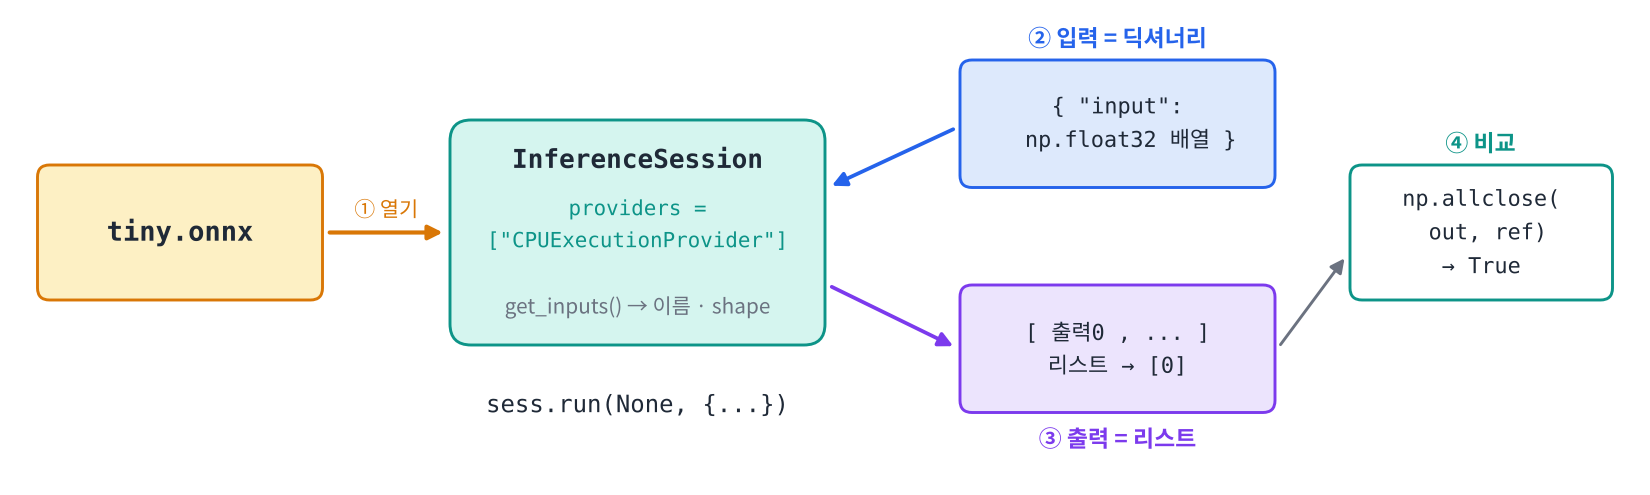

In [ ]:
#@title 🖼 그림 — ONNX Runtime 실행 4단계 — 열기 · 입력 딕셔너리 · 출력 리스트 · 비교
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f4_ort.png", embed=True, width=860))

**문제 4-1** **① 열기** — `InferenceSession(파일, providers=[...])`. providers 는 **어디서 계산할지**입니다. 오늘은 CPU: `"CPUExecutionProvider"`.

In [ ]:
sess = ort.InferenceSession("tiny.onnx", providers=["____"])
print(sess.get_providers())

In [ ]:
assert sess.get_providers() == ["CPUExecutionProvider"]; print("✅")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACnNlc3MgPSBvcnQuSW5mZXJlbmNlU2Vzc2lvbigidGlueS5vbm54Iiwg"
    "cHJvdmlkZXJzPVsiQ1BVRXhlY3V0aW9uUHJvdmlkZXIiXSkKcHJpbnQoc2Vzcy5nZXRfcHJvdmlkZXJzKCkpCgrw"
    "n5KhIO2VtOyEpApHUFUg64qUICJDVURBRXhlY3V0aW9uUHJvdmlkZXIiIChEYXkgMyksIFRlbnNvclJUIOuKlCAi"
    "VGVuc29ycnRFeGVjdXRpb25Qcm92aWRlciIg7J6F64uI64ukLiDsiJzshJwgPSDsmrDshKDsiJzsnIQu"
).decode("utf-8"))

**문제 4-2** **② 입력 이름 알아내기** — ORT 는 입력을 `{이름: 배열}` 딕셔너리로 받습니다. `sess.get_inputs()[0]` 의 `name` · `shape` · `type` 을 출력하세요.

In [ ]:
inp = sess.get_inputs()[0]
in_name = inp.____
print("이름:", in_name, "| shape:", inp.shape, "| type:", inp.type)

In [ ]:
assert in_name == sess.get_inputs()[0].name and inp.shape == [1, 3]; print("✅", in_name)

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmlucCA9IHNlc3MuZ2V0X2lucHV0cygpWzBdCmluX25hbWUgPSBpbnAu"
    "bmFtZQpwcmludCgi7J2066aEOiIsIGluX25hbWUsICJ8IHNoYXBlOiIsIGlucC5zaGFwZSwgInwgdHlwZToiLCBp"
    "bnAudHlwZSkKCvCfkqEg7ZW07ISkCuydtOumhOydgCBleHBvcnQg6rCAIOyekOuPmeycvOuhnCDrtpnsnbgg6rKD"
    "ICjsmIg6IG9ubng6OkdlbW1fMCkuIDXqtZDsi5zsl5DshJwgJ2lucHV0JyDsnLzroZwg67CU6r+J64uI64ukLgp0"
    "eXBlICd0ZW5zb3IoZmxvYXQpJyA9IGZsb2F0MzIg4oCUIE51bVB5IOuwsOyXtOuPhCBmbG9hdDMyIOyXrOyVvCDt"
    "lanri4jri6Qu"
).decode("utf-8"))

**문제 4-3** **③ 실행** — `sess.run(None, {in_name: 배열})`. 입력은 **NumPy 배열** 이어야 합니다 (`torch.Tensor` 는 안 됨). `x1 = [[1, 1, 1]]` 을 넣고, 결과 리스트에서 첫 번째 출력을 꺼내세요.

In [ ]:
outs = sess.run(None, {in_name: x1.____()})
print(type(outs), len(outs))
y_ort = outs[____]
print("ONNX Runtime:", y_ort)

In [ ]:
assert isinstance(y_ort, np.ndarray) and np.allclose(y_ort, [[6.5, -0.5]]); print("✅ 손계산 [6.5, -0.5] 과 같다")

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACm91dHMgPSBzZXNzLnJ1bihOb25lLCB7aW5fbmFtZTogeDEubnVtcHko"
    "KX0pCnByaW50KHR5cGUob3V0cyksIGxlbihvdXRzKSkKeV9vcnQgPSBvdXRzWzBdCnByaW50KCJPTk5YIFJ1bnRp"
    "bWU6IiwgeV9vcnQpCgrwn5KhIO2VtOyEpApydW4g7J2YIOyyqyDsnbjsnpAgTm9uZSA9ICfstpzroKUg7KCE67aA"
    "IOyjvOyEuOyalCcuIOqysOqzvOuKlCDstpzroKUg6rCc7IiY66eM7YG87J2YIOumrOyKpO2KuCDigJQg7Lac66Cl"
    "7J20IO2VmOuCmOyXrOuPhCBbMF0g7Jy866GcIOq6vOuDheuLiOuLpC4KMcK3MSArIDLCtzEgKyAzwrcxICsgMC41"
    "ID0gNi41LCAgMMK3MSDiiJIgMcK3MSArIDHCtzEg4oiSIDAuNSA9IOKIkjAuNS4="
).decode("utf-8"))

### ④ 확인하기 — `==` 대신 `np.allclose`

무작위 입력 여러 개로 PyTorch 와 ORT 를 비교합니다. 두 프로그램은 **같은 식을 다른 순서 · 다른 라이브러리로** 계산하므로 소수점 아래 아주 끝자리가 다를 수 있습니다.

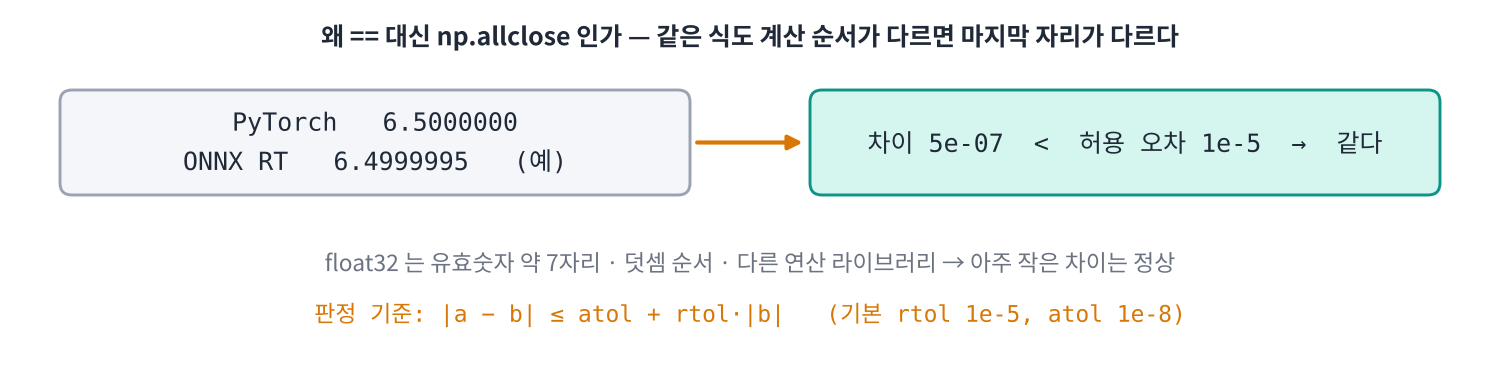

In [ ]:
#@title 🖼 그림 — float32 의 아주 작은 차이 — allclose 로 '같다' 를 판정
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f4_float.png", embed=True, width=820))

**문제 4-4** 배치 1개짜리 난수 입력 20번에 대해 PyTorch 결과 `ref` 와 ORT 결과 `out` 의 **최대 차이**를 구하고, `np.allclose(out, ref, atol=1e-5)` 로 같은지 판정하세요.

In [ ]:
max_diff, same_all = 0.0, True
for _ in range(20):
    xr = torch.randn(1, 3)
    with torch.no_grad():
        ref = tiny(xr).numpy()
    out = sess.run(None, {in_name: xr.numpy()})[0]
    max_diff = max(max_diff, float(np.abs(out - ref).____()))
    same_all = same_all and np.allclose(out, ref, atol=____)
print(f"최대 차이 {max_diff:.2e} | 모두 같다: {same_all}")

In [ ]:
assert same_all and max_diff < 1e-5; print("✅ PyTorch 와 ONNX Runtime 결과가 같다")

In [ ]:
#@title 🔒 정답 보기 4-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTQg4pSA4pSACm1heF9kaWZmLCBzYW1lX2FsbCA9IDAuMCwgVHJ1ZQpmb3IgXyBpbiBy"
    "YW5nZSgyMCk6CiAgICB4ciA9IHRvcmNoLnJhbmRuKDEsIDMpCiAgICB3aXRoIHRvcmNoLm5vX2dyYWQoKToKICAg"
    "ICAgICByZWYgPSB0aW55KHhyKS5udW1weSgpCiAgICBvdXQgPSBzZXNzLnJ1bihOb25lLCB7aW5fbmFtZTogeHIu"
    "bnVtcHkoKX0pWzBdCiAgICBtYXhfZGlmZiA9IG1heChtYXhfZGlmZiwgZmxvYXQobnAuYWJzKG91dCAtIHJlZiku"
    "bWF4KCkpKQogICAgc2FtZV9hbGwgPSBzYW1lX2FsbCBhbmQgbnAuYWxsY2xvc2Uob3V0LCByZWYsIGF0b2w9MWUt"
    "NSkKcHJpbnQoZiLstZzrjIAg7LCo7J20IHttYXhfZGlmZjouMmV9IHwg66qo65GQIOqwmeuLpDoge3NhbWVfYWxs"
    "fSIpCgrwn5KhIO2VtOyEpArstZzrjIAg7LCo7J2064qUIDAg7J206rGw64KYIDFlLTcg7KCV64+EIOKAlCBmbG9h"
    "dDMyIOydmCDrp4jsp4Drp4kg7J6Q66asIOywqOydtOyeheuLiOuLpC4gMWUtNSDrs7Tri6Qg7YGs66m0IGV4cG9y"
    "dCDsl5Ag66y47KCc6rCAIOyeiOuLpOuKlCDsi6DtmLguCifrgrTrs7Trgrgg65KkIOuwmOuTnOyLnCDruYTqtZDt"
    "lZzri6QnIOqwgCDsmKTripgg6rCA7J6lIOykkeyalO2VnCDsirXqtIDsnoXri4jri6Qu"
).decode("utf-8"))

### 바꿔보기 — 일부러 틀려 보기 (에러 메시지 읽기)

아래 두 셀은 **일부러 오류를 냅니다.** 메시지에서 무엇이 잘못됐는지 찾는 연습입니다.

In [ ]:
# ❶ float64 배열을 넣으면?
try:
    sess.run(None, {in_name: np.ones((1, 3))})            # NumPy 기본은 float64
except Exception as e:
    print(type(e).__name__, "→", str(e)[:160])

In [ ]:
# ❷ 입력 이름을 틀리면?
try:
    sess.run(None, {"x": np.ones((1, 3), np.float32)})
except Exception as e:
    print(type(e).__name__, "→", str(e)[:160])

#### ⚠️ 자주 하는 실수

- `sess.run(None, {name: torch_tensor})` → ORT 는 NumPy 만 받습니다. `.numpy()` (GPU 텐서면 `.cpu().numpy()`).
- `np.ones(...)` · `np.array([...])` 는 **float64** → `INVALID_ARGUMENT : Unexpected input data type`. `.astype(np.float32)`.
- 결과를 `outs` 그대로 씀 → 리스트입니다. `outs[0]`.
- `==` 로 비교 → float 는 끝자리가 다를 수 있으니 `np.allclose`.

#### 📌 4교시 정리

- ORT 4단계: `InferenceSession(path, providers)` → `get_inputs()[0].name` → `run(None, {name: np.float32 배열})[0]` → `np.allclose`.
- 입력 = **딕셔너리**, 출력 = **리스트**.
- export 후에는 항상 PyTorch 와 비교한다. 차이 ≈ 1e-7 은 정상.

## 5교시 — 이름 붙이기 · 입력 shape (N, C, H, W)

> 🎬 **애니메이션** [D1-5 입력 shape 맞추기](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html#d1-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

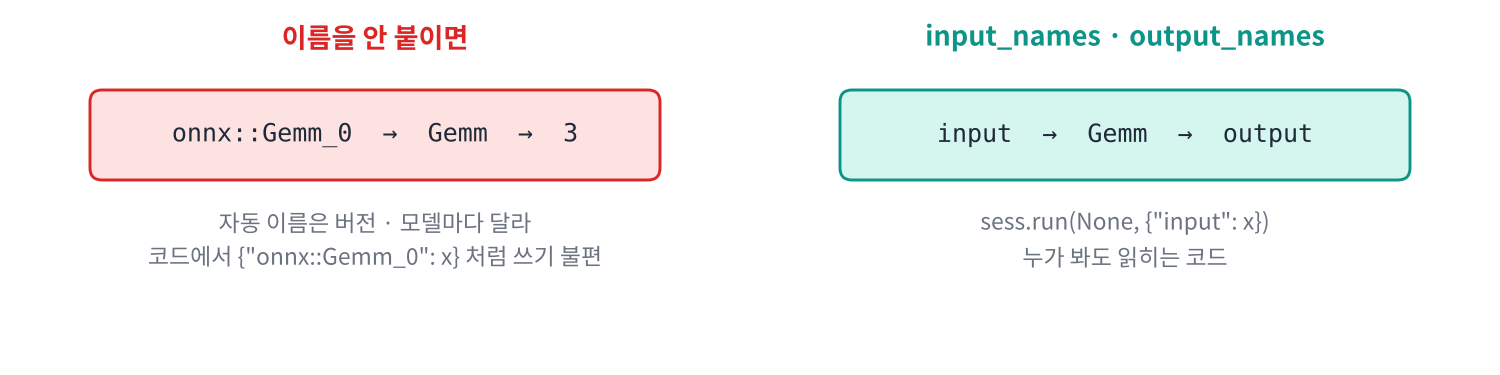

In [ ]:
#@title 🖼 그림 — 자동 이름 대신 input · output 이름 붙이기
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f5_names.png", embed=True, width=760))

**문제 5-1** `input_names` · `output_names` 를 지정해 `tiny_named.onnx` 로 다시 내보내고, ORT 에서 이름을 확인하세요. 두 옵션은 **리스트**입니다 (입력 · 출력이 여러 개일 수 있으므로).

In [ ]:
torch.onnx.export(tiny, dummy, "tiny_named.onnx",
                  input_names=[____], output_names=[____], **EXPORT_KW)
sess_n = ort.InferenceSession("tiny_named.onnx", providers=["CPUExecutionProvider"])
print("입력:", [i.name for i in sess_n.get_inputs()], "| 출력:", [o.name for o in sess_n.get_outputs()])
print(sess_n.run(None, {"input": x1.numpy()})[0])

In [ ]:
assert [i.name for i in sess_n.get_inputs()] == ["input"] and [o.name for o in sess_n.get_outputs()] == ["output"]
print("✅ 이제 {'input': x} 로 부를 수 있다")

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACnRvcmNoLm9ubnguZXhwb3J0KHRpbnksIGR1bW15LCAidGlueV9uYW1l"
    "ZC5vbm54IiwKICAgICAgICAgICAgICAgICAgaW5wdXRfbmFtZXM9WyJpbnB1dCJdLCBvdXRwdXRfbmFtZXM9WyJv"
    "dXRwdXQiXSwgKipFWFBPUlRfS1cpCnNlc3NfbiA9IG9ydC5JbmZlcmVuY2VTZXNzaW9uKCJ0aW55X25hbWVkLm9u"
    "bngiLCBwcm92aWRlcnM9WyJDUFVFeGVjdXRpb25Qcm92aWRlciJdKQpwcmludCgi7J6F66ClOiIsIFtpLm5hbWUg"
    "Zm9yIGkgaW4gc2Vzc19uLmdldF9pbnB1dHMoKV0sICJ8IOy2nOugpToiLCBbby5uYW1lIGZvciBvIGluIHNlc3Nf"
    "bi5nZXRfb3V0cHV0cygpXSkKcHJpbnQoc2Vzc19uLnJ1bihOb25lLCB7ImlucHV0IjogeDEubnVtcHkoKX0pWzBd"
    "KQoK8J+SoSDtlbTshKQK7J2066aE7J2EIOygle2VtCDrkZDrqbQg7Iuk7ZaJIOy9lOuTnOqwgCDrqqjrjbgg67KE"
    "7KCE6rO8IOyDgeq0gOyXhuydtCDqsJnslYTsp5Hri4jri6QuIOydtCDqs7zsoJXsl5DshJzripQg67aE66WYIOuq"
    "qOuNuCA9IGlucHV0IC8gbG9naXRzIOuhnCDthrXsnbztlanri4jri6QgKFZCIERheSA1IOyZgCDqsJnsnYwpLg=="
).decode("utf-8"))

### 이미지 입력의 모양 — (N, C, H, W)

지금까지 입력은 숫자 3개였습니다. 이미지는 4개 축을 가집니다: **N** 장 수(배치) · **C** 채널 · **H** 높이 · **W** 너비. PyTorch · ONNX 모델은 대부분 이 순서입니다.

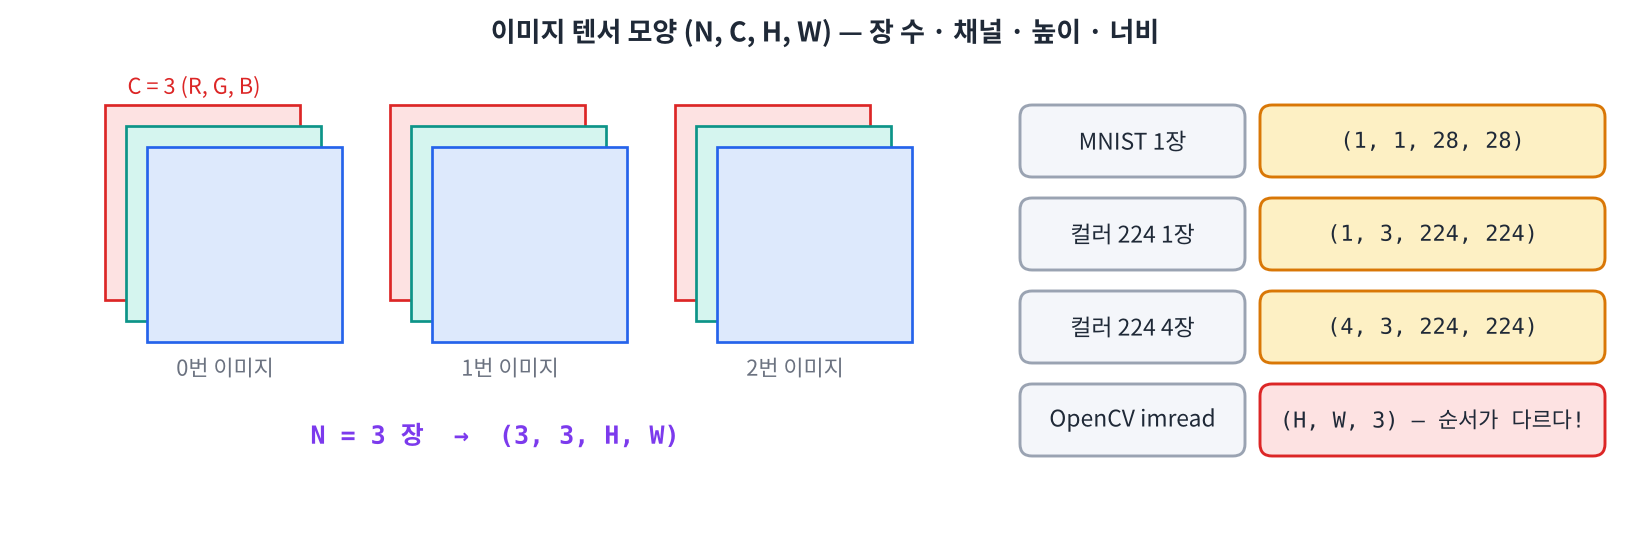

In [ ]:
#@title 🖼 그림 — 이미지 텐서 (N, C, H, W) — OpenCV 는 (H, W, C) 라 순서가 다르다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f5_nchw.png", embed=True, width=860))

**문제 5-2** 각 경우의 모델 입력 shape 를 튜플로 쓰세요.

1. `s1` : MNIST 흑백 28×28 **1장**
2. `s2` : 컬러 224×224 **1장**
3. `s3` : 컬러 224×224 **8장** 한 번에

In [ ]:
s1 = (____)
s2 = (____)
s3 = (____)

In [ ]:
assert s1 == (1, 1, 28, 28) and s2 == (1, 3, 224, 224) and s3 == (8, 3, 224, 224); print("✅", s1, s2, s3)

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACnMxID0gKDEsIDEsIDI4LCAyOCkKczIgPSAoMSwgMywgMjI0LCAyMjQp"
    "CnMzID0gKDgsIDMsIDIyNCwgMjI0KQoK8J+SoSDtlbTshKQK7Z2R67Cx7J2AIEMgPSAxLCDsu6zrn6zripQgQyA9"
    "IDMuIDHsnqXsnbTslrTrj4QgTiA9IDEg7LaV7J20IOuwmOuTnOyLnCDsnojslrTslbwg7ZWp64uI64ukLg=="
).decode("utf-8"))

### 입력 shape 는 export 때 **고정**됩니다

2교시 더미 입력이 `(1, 3)` 이었으므로 `tiny_named.onnx` 는 **배치 1개만** 받습니다. 4개를 한 번에 넣으면 어떻게 될까요?

**문제 5-3** 배치 4개를 넣어 오류 메시지를 출력하고, 메시지에서 **모델이 기대하는 배치 크기**를 찾아 `expected_batch` 에 쓰세요.

In [ ]:
x4 = np.random.rand(4, 3).astype(np.float32)
try:
    sess_n.run(None, {"input": x4})
except Exception as e:
    print(str(e)[:220])
expected_batch = ____

In [ ]:
assert expected_batch == sess_n.get_inputs()[0].shape[0] == 1; print("✅ 이 파일은 배치", expected_batch, "만 받는다")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACng0ID0gbnAucmFuZG9tLnJhbmQoNCwgMykuYXN0eXBlKG5wLmZsb2F0"
    "MzIpCnRyeToKICAgIHNlc3Nfbi5ydW4oTm9uZSwgeyJpbnB1dCI6IHg0fSkKZXhjZXB0IEV4Y2VwdGlvbiBhcyBl"
    "OgogICAgcHJpbnQoc3RyKGUpWzoyMjBdKQpleHBlY3RlZF9iYXRjaCA9IDEKCvCfkqEg7ZW07ISkCuuplOyLnOyn"
    "gOydmCAnR290OiA0IEV4cGVjdGVkOiAxJyDigJQgaW5kZXggMCDstpUo67Cw7LmYKSDsnbQgNCDsnbjrjbAgMSDs"
    "nYQg6riw64yA7ZWp64uI64ukLgrrsLDsuZgg7YGs6riw66W8IOyekOycoOuhreqyjCDrp4zrk5zripQgZHluYW1p"
    "Y19heGVzIOuKlCBEYXkgMiDsl5DshJwg67Cw7JuB64uI64ukLiDsmKTripjsnYAgJzHsnqXslKknIOuEo+yKteuL"
    "iOuLpC4="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `input_names="input"` (문자열) → 리스트 `["input"]` 이어야 합니다.
- 이미지 1장을 `(3, 224, 224)` 로 넣음 → 배치 축이 없어 `Invalid rank`. `[None]` 이나 `np.expand_dims(x, 0)` 으로 N 축 추가.
- OpenCV 이미지 `(H, W, 3)` 을 그대로 넣음 → 순서가 다릅니다. 7교시에서 `transpose(2, 0, 1)`.

#### 📌 5교시 정리

- `input_names=["input"], output_names=["logits"]` — 이름을 붙이면 실행 코드가 단순해진다.
- 이미지 텐서 = **(N, C, H, W)**. 1장이어도 N = 1.
- 입력 shape 는 export 때의 더미 입력으로 **고정**된다 (자유롭게 = Day 2).

## 6교시 — MNIST CNN 내보내기: 같은 4단계를 큰 모델에

VB Day 1 에서 만든 **SimpleConvNet** (433,890 파라미터) 을 가져옵니다. 학습은 이미 해 둔 가중치 `mnist_cnn.pt` 를 내려받습니다 (MNIST test 0.984). 하는 일은 tiny 와 **똑같은 4단계**입니다.

> 🎬 **애니메이션** [D1-6 CNN 그래프와 shape](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html#d1-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
class SimpleConvNet(nn.Module):                 # VB Day 1 8교시와 같은 구조
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 30, 5)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(30 * 12 * 12, 100)
        self.fc2 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))     # (N, 30, 12, 12)
        x = x.flatten(1)                        # (N, 4320)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

cnn = SimpleConvNet()
cnn.load_state_dict(torch.load(fetch("mnist_cnn.pt"), map_location="cpu"))
cnn.eval()
d = np.load(fetch("mnist_sample.npz"))
digits, labels = d["images"], d["labels"]                 # (100, 28, 28) uint8, (100,)
print("파라미터:", f"{sum(p.numel() for p in cnn.parameters()):,}", "| 샘플:", digits.shape, digits.dtype)

plt.figure(figsize=(10, 1.4))
for k in range(10):
    plt.subplot(1, 10, k + 1); plt.imshow(digits[k], cmap="gray"); plt.title(labels[k]); plt.axis("off")
plt.show()

**문제 6-1** **1 내보내기** — `cnn` 을 `mnist_cnn.onnx` 로 내보내세요. 더미 입력은 MNIST 1장 shape (5교시 `s1`), 이름은 `input` / `logits`.

In [ ]:
dummy_mnist = torch.zeros(____)
torch.onnx.export(cnn, dummy_mnist, "mnist_cnn.onnx",
                  input_names=["input"], output_names=[____], **EXPORT_KW)
print(f"mnist_cnn.onnx {os.path.getsize('mnist_cnn.onnx') / 1e6:.2f} MB")

In [ ]:
s = ort.InferenceSession("mnist_cnn.onnx", providers=["CPUExecutionProvider"])
assert s.get_inputs()[0].shape == [1, 1, 28, 28] and s.get_outputs()[0].name == "logits"
print("✅ 433,890 × 4 B =", f"{433_890 * 4 / 1e6:.2f} MB ≈ 파일 크기")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmR1bW15X21uaXN0ID0gdG9yY2guemVyb3MoMSwgMSwgMjgsIDI4KQp0"
    "b3JjaC5vbm54LmV4cG9ydChjbm4sIGR1bW15X21uaXN0LCAibW5pc3RfY25uLm9ubngiLAogICAgICAgICAgICAg"
    "ICAgICBpbnB1dF9uYW1lcz1bImlucHV0Il0sIG91dHB1dF9uYW1lcz1bImxvZ2l0cyJdLCAqKkVYUE9SVF9LVykK"
    "cHJpbnQoZiJtbmlzdF9jbm4ub25ueCB7b3MucGF0aC5nZXRzaXplKCdtbmlzdF9jbm4ub25ueCcpIC8gMWU2Oi4y"
    "Zn0gTUIiKQoK8J+SoSDtlbTshKQK642U66+4IOyeheugpeydgCB6ZXJvcyDsl6zrj4Qg65Cp64uI64ukIOKAlCDq"
    "sJLsnbQg7JWE64uI6528IHNoYXBlIOulvCDrhbntmZTtlZjrr4DroZwuIO2BsCDrqqjrjbjsnYAg7YyM7J28IO2B"
    "rOq4sCDiiYgg7YyM652866+47YSwIMOXIDQgQi4="
).decode("utf-8"))

### 2 열어보기 — Netron 과 코드로

In [ ]:
show_netron("mnist_cnn.onnx", port=8083)

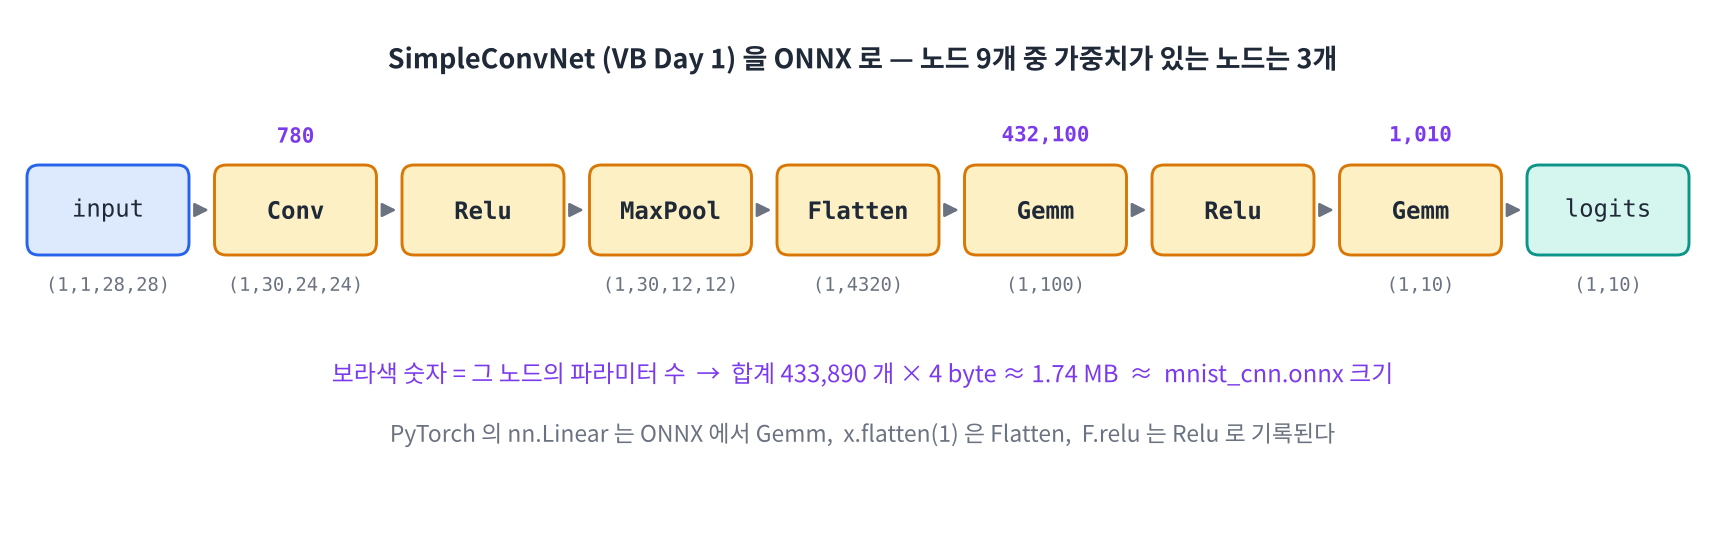

In [ ]:
#@title 🖼 그림 — SimpleConvNet 의 ONNX 그래프 — 노드 순서 · shape · 파라미터
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f6_cnn.png", embed=True, width=900))

**문제 6-2** 노드 종류 목록을 만들고, 그중 **가중치가 있는 노드**(Conv · Gemm) 가 몇 개인지 세세요.

In [ ]:
g = onnx.load("mnist_cnn.onnx").graph
ops = [n.op_type for n in g.node]
n_weighted = sum(op in (____, ____) for op in ops)
print(ops, "| 가중치 노드:", n_weighted)

In [ ]:
assert ops == ["Conv", "Relu", "MaxPool", "Flatten", "Gemm", "Relu", "Gemm"] and n_weighted == 3
print("✅ initializer:", [(i.name, tuple(i.dims)) for i in g.initializer])

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACmcgPSBvbm54LmxvYWQoIm1uaXN0X2Nubi5vbm54IikuZ3JhcGgKb3Bz"
    "ID0gW24ub3BfdHlwZSBmb3IgbiBpbiBnLm5vZGVdCm5fd2VpZ2h0ZWQgPSBzdW0ob3AgaW4gKCJDb252IiwgIkdl"
    "bW0iKSBmb3Igb3AgaW4gb3BzKQpwcmludChvcHMsICJ8IOqwgOykkey5mCDrhbjrk5w6Iiwgbl93ZWlnaHRlZCkK"
    "CvCfkqEg7ZW07ISkCkNvbnYgKDMwwrcxwrc1wrc1ICsgMzAgPSA3ODApLCBHZW1tICg0MzIwwrcxMDAgKyAxMDAp"
    "LCBHZW1tICgxMDDCtzEwICsgMTApIOKAlCAz6rCcLiBSZWx1IMK3IE1heFBvb2wgwrcgRmxhdHRlbiDsnYAg6rCA"
    "7KSR7LmYIOyXhuydjC4KRi5yZWx1IOyymOufvCDtlajsiJjroZwg7JO0IOyXsOyCsOuPhCBubi5SZUxVIOyZgCDr"
    "mJHqsJnsnbQgUmVsdSDrhbjrk5zroZwg64W57ZmU65Cp64uI64ukLg=="
).decode("utf-8"))

**문제 6-3** **3 실행 · 4 확인** — 샘플 100장을 **한 장씩** ORT 로 실행해 예측을 모으고, PyTorch 예측과 **일치율**을 구하세요. 입력은 `uint8 (28, 28)` → `float32 (1, 1, 28, 28)` , 0~1 로 나눈 값입니다.

In [ ]:
sess_cnn = ort.InferenceSession("mnist_cnn.onnx", providers=["CPUExecutionProvider"])
pred_ort, pred_torch = [], []
for img in digits:
    x = (img.astype(np.float32) / ____)[None, None]          # (1, 1, 28, 28)
    pred_ort.append(int(sess_cnn.run(None, {"input": x})[0].argmax()))
    with torch.no_grad():
        pred_torch.append(int(cnn(torch.from_numpy(x)).argmax()))
pred_ort, pred_torch = np.array(pred_ort), np.array(pred_torch)
agree = (pred_ort == pred_torch).____()
acc = (pred_ort == labels).mean()
print(f"ORT–PyTorch 일치율 {agree:.3f} | 정확도 {acc:.3f}")

In [ ]:
assert agree == 1.0 and acc >= 0.95; print("✅ 100장 모두 같은 답")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACnNlc3NfY25uID0gb3J0LkluZmVyZW5jZVNlc3Npb24oIm1uaXN0X2Nu"
    "bi5vbm54IiwgcHJvdmlkZXJzPVsiQ1BVRXhlY3V0aW9uUHJvdmlkZXIiXSkKcHJlZF9vcnQsIHByZWRfdG9yY2gg"
    "PSBbXSwgW10KZm9yIGltZyBpbiBkaWdpdHM6CiAgICB4ID0gKGltZy5hc3R5cGUobnAuZmxvYXQzMikgLyAyNTUp"
    "W05vbmUsIE5vbmVdICAgICAgICAgICMgKDEsIDEsIDI4LCAyOCkKICAgIHByZWRfb3J0LmFwcGVuZChpbnQoc2Vz"
    "c19jbm4ucnVuKE5vbmUsIHsiaW5wdXQiOiB4fSlbMF0uYXJnbWF4KCkpKQogICAgd2l0aCB0b3JjaC5ub19ncmFk"
    "KCk6CiAgICAgICAgcHJlZF90b3JjaC5hcHBlbmQoaW50KGNubih0b3JjaC5mcm9tX251bXB5KHgpKS5hcmdtYXgo"
    "KSkpCnByZWRfb3J0LCBwcmVkX3RvcmNoID0gbnAuYXJyYXkocHJlZF9vcnQpLCBucC5hcnJheShwcmVkX3RvcmNo"
    "KQphZ3JlZSA9IChwcmVkX29ydCA9PSBwcmVkX3RvcmNoKS5tZWFuKCkKYWNjID0gKHByZWRfb3J0ID09IGxhYmVs"
    "cykubWVhbigpCnByaW50KGYiT1JU4oCTUHlUb3JjaCDsnbzsuZjsnKgge2FncmVlOi4zZn0gfCDsoJXtmZXrj4Qg"
    "e2FjYzouM2Z9IikKCvCfkqEg7ZW07ISkCltOb25lLCBOb25lXSDsnYAg7JWe7JeQIOy2lSDrkZAg6rCcKE4sIEMp"
    "IOulvCDstpTqsIAg4oCUICgyOCwgMjgpIOKGkiAoMSwgMSwgMjgsIDI4KS4K67aE66WYIOuqqOuNuOydgCDsiKvs"
    "npAobG9naXRzKSDqsIAg7JWE7KO8IOyhsOq4iCDri6zrnbzrj4QgYXJnbWF4IOqwgCDqsJnsnLzrqbQg6rCZ7J2A"
    "IOuLtSDigJQgJ+yYiOy4oSDsnbzsuZjsnKggMS4wJyDsnbQg65GQIOuyiOynuCDtmZXsnbgg6riw7KSA7J6F64uI"
    "64ukLg=="
).decode("utf-8"))

### 🔁 바꿔보기 — /255 를 빼먹으면?

학습할 때 입력은 0~1 이었습니다. 실행 쪽에서 `/ 255` 를 빼먹으면 어떻게 될까요? **오류 메시지는 하나도 나오지 않습니다.** 정확도만 조용히 떨어집니다 (실행 예: 1.00 → 0.92). 흑백 숫자처럼 쉬운 문제라 이 정도지만, 7교시 컬러 사진에서는 훨씬 크게 틀립니다.

In [ ]:
wrong = [int(sess_cnn.run(None, {"input": img.astype(np.float32)[None, None]})[0].argmax()) for img in digits]
print("/255 없이 정확도:", (np.array(wrong) == labels).mean())

#### ⚠️ 자주 하는 실수

- `img[None, None]` 를 uint8 그대로 넣음 → `Unexpected input data type`. `.astype(np.float32)` 먼저.
- 전처리를 학습 때와 다르게 함 (`/255` 누락 · 정규화 누락) → **오류 없이 틀린 답**. 가장 찾기 어려운 버그.
- `cnn.eval()` 없이 비교 → 이 모델은 Dropout · BN 이 없어 같지만, BN 이 있는 모델(7교시 MobileNetV3 · 8교시 SafetyNet)은 PyTorch 쪽 결과가 달라져 비교가 실패합니다.

#### 📌 6교시 정리

- 큰 모델도 4단계는 같다: export(이름 · 1장 shape) → Netron → ORT run → 일치율.
- `Conv · Relu · MaxPool · Flatten · Gemm · Relu · Gemm` — 가중치 있는 노드 3개, 파일 ≈ 1.74 MB.
- 실행 쪽 전처리는 **학습 때와 똑같이** — 다르면 조용히 틀린다.

## 7교시 — 이미지 한 장 추론: 전처리 6단계 · MobileNetV3

VB Day 5 에서 만든 `mnv3s.onnx` (ImageNet 1000 클래스 MobileNetV3-Small, 입력 `input` 224×224) 로 **실제 사진**을 분류합니다. 런타임에 파일이 없으면 아래 셀이 VB Day 5 와 같은 방법으로 다시 만듭니다.

> 🎬 **애니메이션** [D1-7 사진 → 입력 텐서](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html#d1-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
def get_mnv3s(path="mnv3s.onnx"):
    if not os.path.exists(path):
        print("mnv3s.onnx 가 없어 다시 만듭니다 (VB Day 5 와 같은 설정, 약 20초)")
        m = torchvision.models.mobilenet_v3_small(weights="DEFAULT").eval()
        torch.onnx.export(m, torch.randn(1, 3, 224, 224), path, input_names=["input"], output_names=["logits"],
                          dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, **EXPORT_KW)
    return path

sess_mn = ort.InferenceSession(get_mnv3s(), providers=["CPUExecutionProvider"])
CLASSES = torchvision.models.MobileNet_V3_Small_Weights.DEFAULT.meta["categories"]   # ImageNet 클래스 이름 1000개
print("입력:", sess_mn.get_inputs()[0].name, sess_mn.get_inputs()[0].shape, "| 출력:", sess_mn.get_outputs()[0].shape)
print("클래스 예:", CLASSES[:5], "…", len(CLASSES), "개")

입력 shape 의 첫 축이 `'batch'` 인 것은 VB Day 5 에서 배치 크기를 자유롭게(dynamic) 내보냈기 때문입니다 (Day 2 에서 직접 해 봅니다).

사진 한 장이 모델 입력이 되기까지 **6단계**를 거칩니다. 하나씩 셀을 나눠 만듭니다.

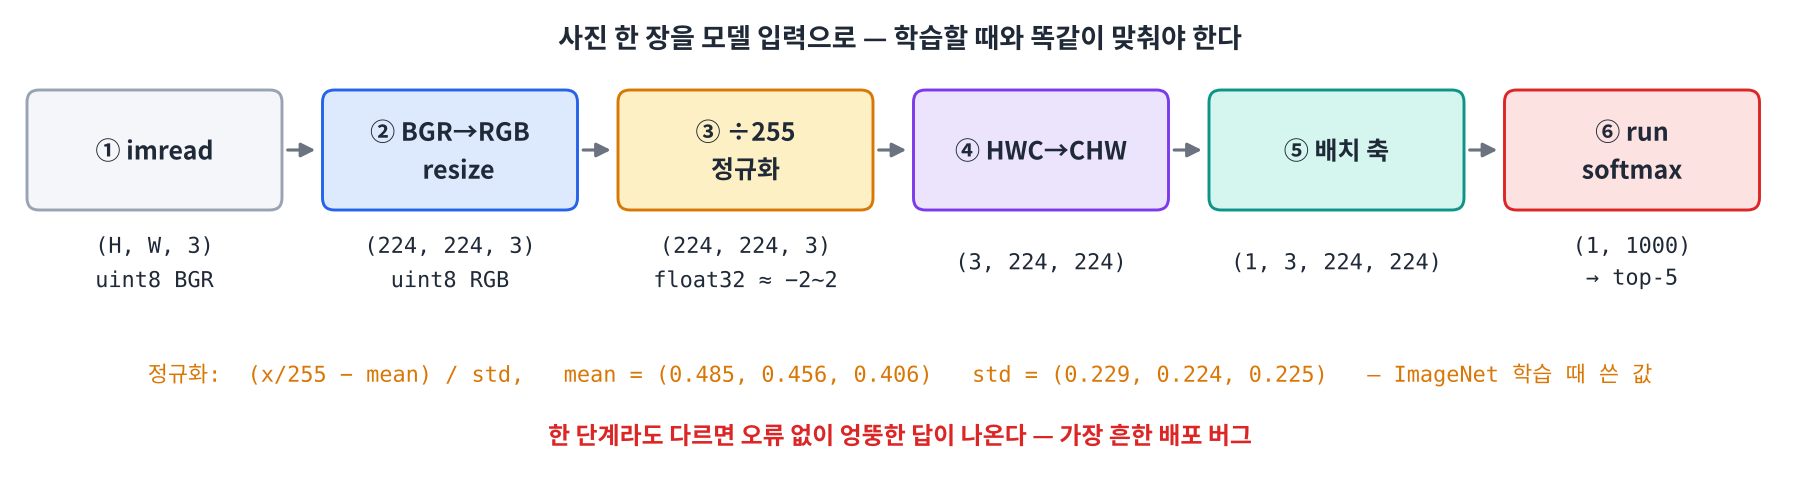

In [ ]:
#@title 🖼 그림 — 사진 한 장을 모델 입력으로 — 전처리 6단계
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f7_pre.png", embed=True, width=900))

In [ ]:
img_bgr = cv2.imread(fetch("butterfly.jpg"))            # ① 읽기
print("① imread :", img_bgr.shape, img_bgr.dtype, "(H, W, C) · BGR 순서")
plt.figure(figsize=(4, 3)); plt.imshow(img_bgr[:, :, ::-1]); plt.axis("off"); plt.show()

**문제 7-1** **② 색 순서 · 크기** — OpenCV 는 **BGR**, 모델은 **RGB** 로 학습했습니다. RGB 로 바꾼 뒤 224×224 로 맞추세요. `cv2.resize` 의 크기는 **(W, H)** 순서입니다.

In [ ]:
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_____2RGB)
img224 = cv2.resize(img_rgb, (____, ____), interpolation=cv2.INTER_AREA)
print("②", img224.shape, img224.dtype)

In [ ]:
assert img224.shape == (224, 224, 3) and img224.dtype == np.uint8
assert np.array_equal(img224, cv2.resize(img_bgr[:, :, ::-1].copy(), (224, 224), interpolation=cv2.INTER_AREA)); print("✅")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmltZ19yZ2IgPSBjdjIuY3Z0Q29sb3IoaW1nX2JnciwgY3YyLkNPTE9S"
    "X0JHUjJSR0IpCmltZzIyNCA9IGN2Mi5yZXNpemUoaW1nX3JnYiwgKDIyNCwgMjI0KSwgaW50ZXJwb2xhdGlvbj1j"
    "djIuSU5URVJfQVJFQSkKcHJpbnQoIuKRoSIsIGltZzIyNC5zaGFwZSwgaW1nMjI0LmR0eXBlKQoK8J+SoSDtlbTs"
    "hKQK7KCV7IKs6rCB7ZiV7Jy866GcIOuKmOumrOuptCDruYTsnKjsnbQg7KGw6riIIOywjOq3uOufrOyngOyngOun"
    "jCwg7Jik64qY7J2AIOuLqOyInO2VmOqyjCDqsJHri4jri6QgKFZCIOqzvOygleydmCBSZXNpemUoMjU2KSArIENl"
    "bnRlckNyb3AoMjI0KSDqsIAg642UIOygle2ZlSku"
).decode("utf-8"))

**문제 7-2** **③ 0~1 · 정규화** — float32 로 바꿔 255 로 나누고, ImageNet **평균을 빼고 표준편차로 나누세요**. `mean` · `std` 는 RGB 채널별 값이라 shape (3,) — (224, 224, 3) 배열의 마지막 축과 자동으로 맞춰집니다 (broadcasting).

In [ ]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)
x = img224.astype(np.float32) / ____
x = (x - ____) / ____
print("③", x.shape, x.dtype, f"범위 {x.min():.2f} ~ {x.max():.2f}")

In [ ]:
assert x.dtype == np.float32 and x.shape == (224, 224, 3)
assert np.allclose(x, (img224 / 255.0 - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225], atol=1e-5); print("✅")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACk1FQU4gPSBucC5hcnJheShbMC40ODUsIDAuNDU2LCAwLjQwNl0sIG5w"
    "LmZsb2F0MzIpClNURCA9IG5wLmFycmF5KFswLjIyOSwgMC4yMjQsIDAuMjI1XSwgbnAuZmxvYXQzMikKeCA9IGlt"
    "ZzIyNC5hc3R5cGUobnAuZmxvYXQzMikgLyAyNTUKeCA9ICh4IC0gTUVBTikgLyBTVEQKcHJpbnQoIuKRoiIsIHgu"
    "c2hhcGUsIHguZHR5cGUsIGYi67KU7JyEIHt4Lm1pbigpOi4yZn0gfiB7eC5tYXgoKTouMmZ9IikKCvCfkqEg7ZW0"
    "7ISkCk1vYmlsZU5ldFYzIOuKlCDsnbQg6rCS7Jy866GcIOygleq3nO2ZlO2VnCBJbWFnZU5ldCDsgqzsp4TsnLzr"
    "oZwg7ZWZ7Iq17ZaI7Iq164uI64ukLiDsoJXqt5ztmZQg7ZuEIOqwkuydgCDrjIDrnrUg4oiSMi4xIH4gMi42LgpN"
    "RUFOIOydhCBmbG9hdDMyIOuhnCDrp4zrk6TslrTslbwg6rKw6rO864+EIGZsb2F0MzIg66GcIOycoOyngOuQqeuL"
    "iOuLpCAoZmxvYXQ2NCDsmYAg7ISe7J2066m0IGZsb2F0NjQg6rCAIOuQqCku"
).decode("utf-8"))

**문제 7-3** **④ HWC → CHW · ⑤ 배치 축** — `(224, 224, 3)` 을 `(3, 224, 224)` 로 축 순서를 바꾸고, 맨 앞에 N 축을 넣어 `(1, 3, 224, 224)` 로 만드세요.

In [ ]:
x_chw = x.transpose(____, ____, ____)          # (H, W, C) → (C, H, W)
x_in = x_chw[____]                              # → (1, 3, 224, 224)
print("④", x_chw.shape, "⑤", x_in.shape, x_in.dtype)

In [ ]:
assert x_in.shape == (1, 3, 224, 224) and x_in.dtype == np.float32 and np.array_equal(x_in[0, 1], x[:, :, 1]); print("✅")

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACnhfY2h3ID0geC50cmFuc3Bvc2UoMiwgMCwgMSkgICAgICAgICAgIyAo"
    "SCwgVywgQykg4oaSIChDLCBILCBXKQp4X2luID0geF9jaHdbTm9uZV0gICAgICAgICAgICAgICAgICAgICAjIOKG"
    "kiAoMSwgMywgMjI0LCAyMjQpCnByaW50KCLikaMiLCB4X2Nody5zaGFwZSwgIuKRpCIsIHhfaW4uc2hhcGUsIHhf"
    "aW4uZHR5cGUpCgrwn5KhIO2VtOyEpAp0cmFuc3Bvc2UoMiwgMCwgMSkgPSAn7IOIIDDrsogg7LaVID0g7JibIDLr"
    "sogoQyksIOyDiCAx67KIID0g7JibIDDrsogoSCksIOyDiCAy67KIID0g7JibIDHrsogoVyknLgp4X2luWzAsIDFd"
    "IChHIOyxhOuEkCDtlZwg7J6lKSDsnbQg7JuQ656YIHhbOiwgOiwgMV0g6rO8IOqwmeydgOyngCDtmZXsnbgg7IWA"
    "7J20IOqygOyCrO2VqeuLiOuLpC4="
).decode("utf-8"))

**문제 7-4** **⑥ 실행 · softmax · top-5** — logits (1, 1000) 을 softmax 로 확률로 바꾸고, 확률이 큰 순서로 5개의 클래스 번호를 구하세요.

In [ ]:
logits = sess_mn.run(None, {"input": x_in})[0][0]           # (1000,)
e = np.exp(logits - logits.max())
prob = e / e.____()
top5 = np.argsort(prob)[::-1][:____]
for k in top5:
    print(f"{prob[k]:.3f}  {CLASSES[k]}")

In [ ]:
assert abs(prob.sum() - 1) < 1e-4 and len(top5) == 5 and prob[top5[0]] == prob.max() and prob[top5[0]] >= prob[top5[4]]
print("✅ top-1:", CLASSES[top5[0]])

In [ ]:
#@title 🔒 정답 보기 7-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTQg4pSA4pSACmxvZ2l0cyA9IHNlc3NfbW4ucnVuKE5vbmUsIHsiaW5wdXQiOiB4X2lu"
    "fSlbMF1bMF0gICAgICAgICAgICMgKDEwMDAsKQplID0gbnAuZXhwKGxvZ2l0cyAtIGxvZ2l0cy5tYXgoKSkKcHJv"
    "YiA9IGUgLyBlLnN1bSgpCnRvcDUgPSBucC5hcmdzb3J0KHByb2IpWzo6LTFdWzo1XQpmb3IgayBpbiB0b3A1Ogog"
    "ICAgcHJpbnQoZiJ7cHJvYltrXTouM2Z9ICB7Q0xBU1NFU1trXX0iKQoK8J+SoSDtlbTshKQKbG9naXRzLm1heCgp"
    "IOulvCDrubzripQg6rKD7J2AIGV4cCDqsIAg64SI66y0IOy7pOyngOuKlCDqsoMob3ZlcmZsb3cpIOydhCDrp4nr"
    "ipQgTk4g6rO87KCV7J2YIOq3uCDrsKnrspXsnoXri4jri6QuCmFyZ3NvcnQg64qUIOyekeydgCDsiJzshJwg4oaS"
    "IFs6Oi0xXSDroZwg65Kk7KeR7Ja0IO2BsCDsiJzshJwg4oaSIOyVnuyXkOyEnCA16rCcLg=="
).decode("utf-8"))

### 함수로 묶기 — 다른 사진에도 쓰기

지금까지의 단계를 `preprocess` · `classify` 두 함수로 묶습니다. 8교시 미니 프로젝트에서 그대로 씁니다.

In [ ]:
def preprocess(img_bgr, size=224):
    img = cv2.resize(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), (size, size), interpolation=cv2.INTER_AREA)
    x = (img.astype(np.float32) / 255 - MEAN) / STD
    return x.transpose(2, 0, 1)[None]                        # (1, 3, size, size) float32

def classify(sess, img_bgr, k=5):
    logits = sess.run(None, {"input": preprocess(img_bgr)})[0][0]
    p = np.exp(logits - logits.max()); p /= p.sum()
    top = np.argsort(p)[::-1][:k]
    return [(CLASSES[i], float(p[i])) for i in top]

plt.figure(figsize=(12, 3.6))
for j, name in enumerate(["butterfly.jpg", "orange.jpg", "baboon.jpg"]):
    im = cv2.imread(fetch(name)); res = classify(sess_mn, im, 3)
    plt.subplot(1, 3, j + 1); plt.imshow(im[:, :, ::-1]); plt.axis("off")
    plt.title("\n".join(f"{c} {p:.2f}" for c, p in res), fontsize=9)
plt.tight_layout(); plt.show()

### 🔁 바꿔보기 — 전처리를 하나씩 빼먹으면?

아래 셀은 전처리를 **일부러 틀리게** 한 세 가지 경우의 top-1 을 비교합니다. 어떤 실수가 가장 크게 망가뜨리나요?

In [ ]:
im = cv2.imread(fetch("orange.jpg"))
def top1(x): l = sess_mn.run(None, {"input": x})[0][0]; return CLASSES[int(l.argmax())]
good = preprocess(im)
bgr = preprocess(im[:, :, ::-1].copy())                                    # BGR→RGB 를 안 한 것과 같음
no_norm = (cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), (224, 224)).astype(np.float32) / 255).transpose(2, 0, 1)[None]
no_255 = ((cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), (224, 224)).astype(np.float32) - MEAN) / STD).transpose(2, 0, 1)[None]
for name, x_ in [("올바른 전처리", good), ("BGR 그대로", bgr), ("정규화 없음", no_norm), ("/255 없음", no_255)]:
    print(f"{name:10s} → {top1(x_)}")

#### ⚠️ 자주 하는 실수

- `cv2.resize(img, (H, W))` → OpenCV 크기는 **(W, H)**. 정사각형이면 티가 안 나서 더 위험합니다.
- `x.reshape(3, 224, 224)` 로 축을 바꿈 → reshape 는 **모양만** 바꿉니다. 축 순서는 `transpose`.
- `MEAN = np.array([0.485, ...])` (float64) → 결과가 float64 가 되어 ORT 오류.
- 결과를 `argmax` 만 보고 끝냄 → top-5 와 확률을 보면 모델이 얼마나 확신하는지 알 수 있습니다.

#### 📌 7교시 정리

- 전처리 6단계: imread → BGR→RGB · resize(W, H) → /255 · 정규화 → HWC→CHW → 배치 축 → run · softmax.
- 전처리는 ONNX 밖의 코드 — 학습 때와 **같은 순서 · 같은 값**이어야 한다.
- `preprocess` · `classify` 두 함수로 묶어 두면 어떤 사진에도 쓸 수 있다.

## 8교시 — 미니 프로젝트: 혼자서 4단계 · 채점

오늘 반복한 4단계를 **처음 보는 모델**에 혼자 적용합니다. 모델은 현장 안전 카메라용으로 가정한 작은 CNN **`SafetyNet`** — 64×64 컬러 사진을 받아 3가지(`safe` · `warning` · `danger`) 로 분류합니다. (가중치는 seed 로 고정한 연습용 값입니다. 정확도가 아니라 **배포 과정**이 과제입니다.)

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | `SafetyNet` 을 ONNX 로 내보내기 (이름 `input` / `logits`, 1장) | 20 |
| 2 | 그래프 요약 — 노드 종류 · 가중치 노드 수 · 파라미터 수 | 20 |
| 3 | ORT 실행 · PyTorch 와 비교 (난수 입력 10개) | 20 |
| 4 | `onnx_report(path)` — 파일 · 입력 · 출력 정보를 딕셔너리로 | 20 |
| 5 | 사진 3장을 64×64 로 전처리해 ORT 로 분류 | 10 |
| 6 | 결과 해석 (마크다운 답변) | 10 |

과제 끝의 **채점 셀**을 실행하면 자동 채점 점수가 나옵니다(과제 6 은 강사 채점). 제출은 채점 셀 결과가 보이는 상태로 이 노트북을 공유합니다.

> 🎬 **애니메이션** [D1-8 4단계 정리](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/animation.html#d1-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/OT-day1/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

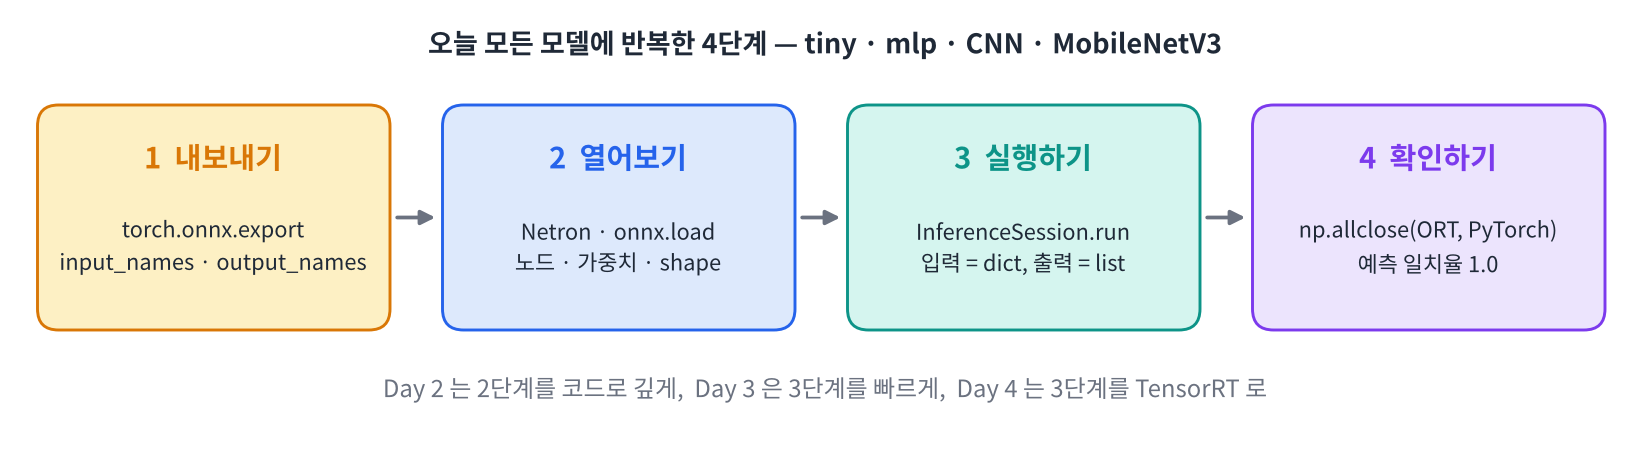

In [ ]:
#@title 🖼 그림 — 오늘 모든 모델에 반복한 4단계
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/OT-day1/img/f8_three.png", embed=True, width=860))

In [ ]:
class SafetyNet(nn.Module):
    """64×64 컬러 → 3 클래스. Conv-BN-ReLU-Pool 두 번 + 분류기"""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),    # → (8, 32, 32)
            nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),  # → (16, 16, 16)
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, 3))

    def forward(self, x):
        return self.head(self.features(x))

SAFETY = ["safe", "warning", "danger"]
torch.manual_seed(7)
safety = SafetyNet()
with torch.no_grad():                                   # BN 통계를 연습용 값으로 채운다
    for m_ in safety.modules():
        if isinstance(m_, nn.BatchNorm2d):
            m_.running_mean.uniform_(-0.2, 0.2); m_.running_var.uniform_(0.5, 1.5)
print(safety)

### 과제 1 — 내보내기 (20점)

`safety` 를 **실행 모드**로 바꾼 뒤 `safety.onnx` 로 내보내세요. 입력은 컬러 64×64 **1장**, 이름은 `input` / `logits`.

In [ ]:
safety.____()
torch.onnx.export(safety, torch.randn(____), "safety.onnx",
                  input_names=____, output_names=____, **EXPORT_KW)
print(f"safety.onnx {os.path.getsize('safety.onnx'):,} B")

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACnNhZmV0eS5ldmFsKCkKdG9yY2gub25ueC5leHBvcnQoc2FmZXR5LCB0"
    "b3JjaC5yYW5kbigxLCAzLCA2NCwgNjQpLCAic2FmZXR5Lm9ubngiLAogICAgICAgICAgICAgICAgICBpbnB1dF9u"
    "YW1lcz1bImlucHV0Il0sIG91dHB1dF9uYW1lcz1bImxvZ2l0cyJdLCAqKkVYUE9SVF9LVykKcHJpbnQoZiJzYWZl"
    "dHkub25ueCB7b3MucGF0aC5nZXRzaXplKCdzYWZldHkub25ueCcpOix9IEIiKQoK8J+SoSDtlbTshKQKZXhwb3J0"
    "IOuKlCDquLDrs7jqsJLsnLzroZwg7Iuk7ZaJIOuqqOuTnCDqt7jrnpjtlITrpbwg64W57ZmU7ZWY66+A66GcIGV2"
    "YWwoKSDsnYQg67m864+EIOq3uOuemO2UhOuKlCDqsJnsirXri4jri6QuIO2VmOyngOunjCBzYWZldHkg6rCAIO2V"
    "meyKtSDrqqjrk5zroZwg64Ko7JWEIOyeiOycvOuptArqs7zsoJwgMyDsl5DshJwgUHlUb3JjaCDqsrDqs7zqsIAg"
    "QmF0Y2hOb3JtICfsp4DquIgg65Ok7Ja07JioIOuwsOy5mOydmCDthrXqs4QnIOuhnCDqs4TsgrDrkJjqs6AgcnVu"
    "bmluZyDtj4nqt6DquYzsp4Ag67CU64CM7Ja0IE9SVCDsmYAg7YGs6rKMIOuLrOudvOynkeuLiOuLpCAo7Iuk7ZaJ"
    "IOyYiCDstZzrjIAg7LCo7J20IDAuNTcpLgrqt7jrnpjshJwgZXhwb3J0IOyghOyXkCDtla3sg4EgZXZhbCgpLg=="
).decode("utf-8"))

### 과제 2 — 그래프 요약 (20점)

`safety.onnx` 를 열어 노드 종류 목록 `ops`, 가중치가 있는 노드(Conv · Gemm) 수 `n_weighted`, PyTorch 파라미터 수 `n_params` 를 구하세요. **실행 후** Netron 으로도 열어 보고, `BatchNormalization` 노드가 보이는지 확인하세요.

In [ ]:
g_s = onnx.load("safety.onnx").graph
ops = [n.____ for n in g_s.node]
n_weighted = sum(op in ("Conv", "Gemm") for op in ____)
n_params = sum(p.numel() for p in safety.____())
print(ops)
print("가중치 노드:", n_weighted, "| 파라미터:", n_params)

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACmdfcyA9IG9ubngubG9hZCgic2FmZXR5Lm9ubngiKS5ncmFwaApvcHMg"
    "PSBbbi5vcF90eXBlIGZvciBuIGluIGdfcy5ub2RlXQpuX3dlaWdodGVkID0gc3VtKG9wIGluICgiQ29udiIsICJH"
    "ZW1tIikgZm9yIG9wIGluIG9wcykKbl9wYXJhbXMgPSBzdW0ocC5udW1lbCgpIGZvciBwIGluIHNhZmV0eS5wYXJh"
    "bWV0ZXJzKCkpCnByaW50KG9wcykKcHJpbnQoIuqwgOykkey5mCDrhbjrk5w6Iiwgbl93ZWlnaHRlZCwgInwg7YyM"
    "652866+47YSwOiIsIG5fcGFyYW1zKQoK8J+SoSDtlbTshKQK6riw7KG0IOuwqeyLnSBleHBvcnQg64qUIGV2YWwg"
    "66qo65Oc7J2YIENvbnYg65KkIEJhdGNoTm9ybSDsnYQgQ29udiDsl5Ag7ZWp7LOQKGZ1c2UpIOuyhOumveuLiOuL"
    "pCDigJQg6re4656Y7IScIEJhdGNoTm9ybWFsaXphdGlvbiDrhbjrk5zqsIAg67O07J207KeAIOyViuyKteuLiOuL"
    "pC4K6rCZ7J2AIOqzhOyCsOydhCDrjZQg7KCB7J2AIOuFuOuTnOuhnCDtlZjripQg7J2065+wICftlansuZjquLAn"
    "IOqwgCBEYXkgMyDCtyA0IOyXkOyEnCDruajrnbzsp4DripQg7J207JygIOykkSDtlZjrgpjsnoXri4jri6Qu"
).decode("utf-8"))

In [ ]:
show_netron("safety.onnx", port=8084)

### 과제 3 — 실행 · 비교 (20점)

ORT 세션 `sess_s` 를 만들고, `torch.randn(1, 3, 64, 64)` 난수 입력 10개에 대해 PyTorch 와의 **최대 차이** `diff_s` 를 구하세요.

In [ ]:
sess_s = ort.InferenceSession("safety.onnx", providers=[____])
diff_s = 0.0
for _ in range(10):
    xr = torch.randn(1, 3, 64, 64)
    with torch.no_grad():
        ref = safety(xr).numpy()
    out = sess_s.run(None, {____: xr.numpy()})[0]
    diff_s = max(diff_s, float(np.abs(out - ref).max()))
print(f"최대 차이 {diff_s:.2e} | allclose: {diff_s < 1e-4}")

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACnNlc3NfcyA9IG9ydC5JbmZlcmVuY2VTZXNzaW9uKCJzYWZldHkub25u"
    "eCIsIHByb3ZpZGVycz1bIkNQVUV4ZWN1dGlvblByb3ZpZGVyIl0pCmRpZmZfcyA9IDAuMApmb3IgXyBpbiByYW5n"
    "ZSgxMCk6CiAgICB4ciA9IHRvcmNoLnJhbmRuKDEsIDMsIDY0LCA2NCkKICAgIHdpdGggdG9yY2gubm9fZ3JhZCgp"
    "OgogICAgICAgIHJlZiA9IHNhZmV0eSh4cikubnVtcHkoKQogICAgb3V0ID0gc2Vzc19zLnJ1bihOb25lLCB7Imlu"
    "cHV0IjogeHIubnVtcHkoKX0pWzBdCiAgICBkaWZmX3MgPSBtYXgoZGlmZl9zLCBmbG9hdChucC5hYnMob3V0IC0g"
    "cmVmKS5tYXgoKSkpCnByaW50KGYi7LWc64yAIOywqOydtCB7ZGlmZl9zOi4yZX0gfCBhbGxjbG9zZToge2RpZmZf"
    "cyA8IDFlLTR9Iik="
).decode("utf-8"))

### 과제 4 — `onnx_report` (20점)

ONNX 파일 경로를 받아 아래 키를 가진 **딕셔너리**를 돌려주는 함수를 만드세요. 앞으로 모든 모델을 이 함수로 먼저 살펴봅니다.

| 키 | 값 | `safety.onnx` 의 경우 |
|---|---|---|
| `"size_kb"` | 파일 크기 (KB, 소수 1자리 반올림) | |
| `"n_nodes"` | 노드 수 | |
| `"ops"` | 노드 종류 **중복 없이 정렬한** 리스트 | `['Conv', 'Flatten', ...]` |
| `"inputs"` | `[(이름, shape), ...]` — ORT 세션에서 | `[('input', [1, 3, 64, 64])]` |
| `"outputs"` | `[(이름, shape), ...]` | `[('logits', [1, 3])]` |

In [ ]:
def onnx_report(path):
    model = onnx.load(path)
    s = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    return {
        "size_kb": round(os.path.getsize(path) / 1024, ____),
        "n_nodes": len(model.graph.____),
        "ops": sorted(set(n.op_type for n in model.graph.node)),
        "inputs": [(i.name, i.shape) for i in s.____()],
        "outputs": [(o.name, o.shape) for o in s.____()],
    }

for p in ["tiny_named.onnx", "mnist_cnn.onnx", "safety.onnx"]:
    print(p, onnx_report(p))

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSACmRlZiBvbm54X3JlcG9ydChwYXRoKToKICAgIG1vZGVsID0gb25ueC5s"
    "b2FkKHBhdGgpCiAgICBzID0gb3J0LkluZmVyZW5jZVNlc3Npb24ocGF0aCwgcHJvdmlkZXJzPVsiQ1BVRXhlY3V0"
    "aW9uUHJvdmlkZXIiXSkKICAgIHJldHVybiB7CiAgICAgICAgInNpemVfa2IiOiByb3VuZChvcy5wYXRoLmdldHNp"
    "emUocGF0aCkgLyAxMDI0LCAxKSwKICAgICAgICAibl9ub2RlcyI6IGxlbihtb2RlbC5ncmFwaC5ub2RlKSwKICAg"
    "ICAgICAib3BzIjogc29ydGVkKHNldChuLm9wX3R5cGUgZm9yIG4gaW4gbW9kZWwuZ3JhcGgubm9kZSkpLAogICAg"
    "ICAgICJpbnB1dHMiOiBbKGkubmFtZSwgaS5zaGFwZSkgZm9yIGkgaW4gcy5nZXRfaW5wdXRzKCldLAogICAgICAg"
    "ICJvdXRwdXRzIjogWyhvLm5hbWUsIG8uc2hhcGUpIGZvciBvIGluIHMuZ2V0X291dHB1dHMoKV0sCiAgICB9Cgpm"
    "b3IgcCBpbiBbInRpbnlfbmFtZWQub25ueCIsICJtbmlzdF9jbm4ub25ueCIsICJzYWZldHkub25ueCJdOgogICAg"
    "cHJpbnQocCwgb25ueF9yZXBvcnQocCkp"
).decode("utf-8"))

### 과제 5 — 사진 3장 분류 (10점)

7교시 `preprocess` 를 **size=64** 로 써서 사진 3장을 `sess_s` 로 분류하고, 클래스 이름을 `safety_preds` 리스트에 모으세요. (연습용 가중치라 결과의 '정답' 은 없습니다 — 입력 모양과 흐름이 과제입니다.)

In [ ]:
safety_preds = []
for name in ["butterfly.jpg", "orange.jpg", "baboon.jpg"]:
    x_s = preprocess(cv2.imread(fetch(name)), size=____)
    logits_s = sess_s.run(None, {"input": x_s})[0]
    safety_preds.append(SAFETY[int(logits_s.____())])
    print(name, x_s.shape, "→", safety_preds[-1], logits_s.round(3))

In [ ]:
#@title 🔒 정답 보기 8-5 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTUg4pSA4pSACnNhZmV0eV9wcmVkcyA9IFtdCmZvciBuYW1lIGluIFsiYnV0dGVyZmx5"
    "LmpwZyIsICJvcmFuZ2UuanBnIiwgImJhYm9vbi5qcGciXToKICAgIHhfcyA9IHByZXByb2Nlc3MoY3YyLmltcmVh"
    "ZChmZXRjaChuYW1lKSksIHNpemU9NjQpCiAgICBsb2dpdHNfcyA9IHNlc3Nfcy5ydW4oTm9uZSwgeyJpbnB1dCI6"
    "IHhfc30pWzBdCiAgICBzYWZldHlfcHJlZHMuYXBwZW5kKFNBRkVUWVtpbnQobG9naXRzX3MuYXJnbWF4KCkpXSkK"
    "ICAgIHByaW50KG5hbWUsIHhfcy5zaGFwZSwgIuKGkiIsIHNhZmV0eV9wcmVkc1stMV0sIGxvZ2l0c19zLnJvdW5k"
    "KDMpKQ=="
).decode("utf-8"))

### 과제 6 — 결과 해석 (10점)

아래 셀에 답을 쓰세요.

1. `safety.onnx` 를 Netron 으로 열면 `BatchNormalization` 노드가 없습니다. PyTorch 모델에는 BN 이 있는데 왜 없을까요? 과제 1 에서 `eval()` 을 빼면 과제 3 비교가 어떻게 될지도 쓰세요.
2. 과제 3 의 최대 차이가 0 이 아닌데도 "같다" 고 판단해도 되는 이유는?
3. 오늘 만든 `preprocess` 를 현장 카메라 장치에 옮길 때, ONNX 파일과 **함께 전달해야 할 정보** 3가지는? (힌트: 7교시 6단계)
4. 6교시 `/255 없음` · 7교시 `BGR 그대로` 실험처럼 **오류 없이 틀리는** 경우를 미리 잡으려면 배포 전에 무엇을 확인해야 할까요?

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4gZXZhbCDrqqjrk5zsnZggQk4g7J2AIOqzoOygleuQnCDtj4nqt6Agwrcg"
    "67aE7IKw7Jy866GcICfqs7HtlZjqs6Ag642U7ZWY6riwJyDrp4wg7ZWY66+A66GcLCDrsJTroZwg7JWeIENvbnYg"
    "7J2YIOqwgOykkey5mCDCtyBiaWFzIOyXkCDrr7jrpqwg7ZWp7LOQIOuEo+ydhCDsiJgg7J6I7Iq164uI64ukIChD"
    "b252LUJOIGZ1c2lvbikuCiAgIOq4sOyhtCDrsKnsi50gZXhwb3J0IOqwgCDsnbQg7ZWp7LmY6riw66W8IO2VtOyE"
    "nCBCTiDrhbjrk5zqsIAg7IKs65287KeR64uI64ukLiBleHBvcnQg64qUIOq4sOuzuOqwkuycvOuhnCDsi6Ttlokg"
    "66qo65OcIOq3uOuemO2UhOulvCDrhbntmZTtlZjrr4DroZwgZXZhbCgpIOydhCDrubzrj4Qg6re4656Y7ZSE64qU"
    "IOqwmeyngOunjCwKICAgc2FmZXR5IOqwgCDtlZnsirUg66qo65Oc66GcIOuCqOyVhCBQeVRvcmNoIOqysOqzvOqw"
    "gCDrsLDsuZgg7Ya16rOE66GcIOqzhOyCsOuQmOyWtCDqs7zsoJwgMyDruYTqtZAoYWxsY2xvc2UpIOqwgCDsi6Tt"
    "jKjtlanri4jri6QgKOyLpO2WiSDsmIgg7LWc64yAIOywqOydtCAwLjU3KS4KMi4gZmxvYXQzMiDripQg7Jyg7Zqo"
    "7Iir7J6Q6rCAIOyVvSA37J6Q66as7J206rOgLCBCTiDtlansuZjquLAgwrcg7Jew7IKwIOyInOyEnCDssKjsnbTr"
    "oZwg64Gd7J6Q66as6rCAIOuLrOudvOyniCDsiJgg7J6I7Iq164uI64ukLiDssKjsnbTqsIAgMWUtNX4xZS02IOyI"
    "mOykgOydtOqzoCBhcmdtYXgo7JiI7LihKSDqsIAg6rCZ7Jy866m0IOqwmeydgCDrqqjrjbjsnoXri4jri6QuCjMu"
    "IOyeheugpSDtgazquLAoNjTDlzY0IMK3IDIyNMOXMjI0KSDsmYAgcmVzaXplIOuwqeyLnSwg7IOJIOyInOyEnChS"
    "R0IpIOyZgCAwfjEg7Iqk7LyA7J28LCDsoJXqt5ztmZQgbWVhbiDCtyBzdGQsICjqt7jrpqzqs6Ag7J6F66ClIOyd"
    "tOumhCDCtyDstpUg7Iic7IScIE5DSFcgwrcg7YG0656Y7IqkIOydtOumhCDrqqnroZ0pLgo0LiDqsJnsnYAg7IKs"
    "7KeEIOuqhyDsnqXsnYQgUHlUb3JjaCjtlZnsirUg65WMIOyghOyymOumrCkg7JmAIOuwsO2PrCDsvZTrk5woT05O"
    "WCArIOyDiCDsoITsspjrpqwpIOyWkeyqveyXkCDrhKPslrQgdG9wLTEgwrcg7ZmV66Wg7J20IOqwmeydgOyngCDr"
    "uYTqtZDtlZjripQgJ+qzqOuToCDsg5jtlIwnIO2FjOyKpO2KuOulvCDrp4zrk63ri4jri6QuCiAgIOyIq+yekCDr"
    "uYTqtZAg6riw7KSAKGFsbGNsb3NlIMK3IOyYiOy4oSDsnbzsuZjsnKgpIOydhCDsoJXtlbQg65GQ6rOgLCDsoITs"
    "spjrpqwg7L2U65Oc66W8IOuwlOq/gCDrlYzrp4jri6Qg64uk7IucIOuPjOumveuLiOuLpC4="
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    s_ = ort.InferenceSession("safety.onnx", providers=["CPUExecutionProvider"])
    assert [i.name for i in s_.get_inputs()] == ["input"] and s_.get_inputs()[0].shape == [1, 3, 64, 64]
    assert [o.name for o in s_.get_outputs()] == ["logits"] and not safety.training
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", e)
try:
    assert ops == [n.op_type for n in onnx.load("safety.onnx").graph.node] and "BatchNormalization" not in ops
    assert n_weighted == 3 and n_params == sum(p.numel() for p in SafetyNet().parameters())
    score += 20; print("✅ 과제 2  +20", f"(노드 {len(ops)}개 · 파라미터 {n_params:,})")
except Exception as e: print("❌ 과제 2", e)
try:
    xr = torch.randn(1, 3, 64, 64)
    with torch.no_grad(): ref = safety(xr).numpy()
    assert diff_s < 1e-4 and np.allclose(sess_s.run(None, {"input": xr.numpy()})[0], ref, atol=1e-4)
    score += 20; print("✅ 과제 3  +20", f"(최대 차이 {diff_s:.1e})")
except Exception as e: print("❌ 과제 3", e)
try:
    r = onnx_report("safety.onnx")
    assert r["inputs"] == [("input", [1, 3, 64, 64])] and r["outputs"] == [("logits", [1, 3])]
    assert r["n_nodes"] == len(onnx.load("safety.onnx").graph.node) and r["ops"] == sorted(set(r["ops"]))
    assert r["size_kb"] == round(os.path.getsize("safety.onnx") / 1024, 1)
    assert onnx_report("mnist_cnn.onnx")["ops"] == ["Conv", "Flatten", "Gemm", "MaxPool", "Relu"]
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", e)
try:
    assert len(safety_preds) == 3 and all(p in SAFETY for p in safety_preds) and x_s.shape == (1, 3, 64, 64)
    expect = [SAFETY[int(sess_s.run(None, {"input": preprocess(cv2.imread(fetch(n)), 64)})[0].argmax())]
              for n in ["butterfly.jpg", "orange.jpg", "baboon.jpg"]]
    assert safety_preds == expect
    score += 10; print("✅ 과제 5  +10")
except Exception as e: print("❌ 과제 5", e)
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점)")

### 🔎 더 알아보기 — ONNX 는 정말 '어디서나' 돌까?

오늘 만든 `.onnx` 는 ONNX Runtime 이 있는 곳이면 Windows · Linux · Android · 웹 브라우저(onnxruntime-web) 어디서나 같은 결과를 냅니다. 단, 실행기마다 **지원하는 연산(opset)** 이 조금씩 다릅니다. 파일의 opset 은 `onnx.load(path).opset_import` 로 볼 수 있고, Day 2 에서 opset 과 지원되지 않는 연산 문제를 직접 만나 고칩니다.

#### 📌 8교시 정리

- 처음 보는 모델도 4단계: eval → export(이름 · shape) → Netron · `onnx_report` → ORT 실행 · allclose.
- eval 모드 export 는 Conv 뒤 BN 을 합친다 — 그래프가 PyTorch 코드와 똑같이 생기지 않을 수 있다.
- 배포 = ONNX 파일 + **전처리 규칙** + 클래스 이름. 셋 다 전달해야 한다.

## 오늘의 정리

### 셀프 체크

- [ ] 학습 환경과 실행 환경이 다른 이유, `.pt` 와 `.onnx` 의 차이를 말할 수 있다
- [ ] `torch.onnx.export(model, dummy, path, input_names=..., output_names=...)` 를 쓸 수 있고, 더미 입력의 역할을 설명할 수 있다
- [ ] Netron 에서 노드 · 화살표 · 가중치(initializer) · 입출력 shape 를 읽을 수 있다
- [ ] `nn.Linear → Gemm`, `nn.ReLU → Relu` 처럼 PyTorch 연산이 어떤 노드가 되는지 말할 수 있다
- [ ] `InferenceSession → get_inputs → run → np.allclose` 를 쓸 수 있다 (입력 dict · 출력 list · float32)
- [ ] 이미지 텐서 (N, C, H, W) 와 OpenCV (H, W, C) 의 차이를 설명할 수 있다
- [ ] 사진 한 장의 전처리 6단계를 순서대로 말하고 코드로 쓸 수 있다
- [ ] 전처리를 틀리면 **오류 없이** 틀린 답이 나온다는 것을 실험으로 보였다

### 내일 (Day 2) 예고

오늘 Netron 으로 본 그래프를 **코드로** 샅샅이 읽는 `describe_onnx()` 를 만들고, 오늘 5교시에서 막힌 **배치 크기 고정**을 `dynamic_axes` 로 풉니다. 일부러 실패하는 export 3가지를 만나 고치고, 그래프 단순화로 노드 수를 줄여 봅니다. 오늘 만든 **`preprocess` · `onnx_report` 를 그대로** 씁니다 — Drive 에 노트북 사본을 꼭 저장해 두세요.